# $H\rightarrow b\bar{b}$ via Machine Learning 
This notebook consists of two sections: teaching material and student independent work. The independent work is based on the framework provided in the UCL teaching material, which demonstrates how to use the given functions and how to import the relevant data. The tutorial sections serve as guidance for implementing the analysis workflow, while the optimisation choices, selection criteria, and evaluation steps were performed independently.
## Teaching material
### 3.1 Importing libraries and loading 


In [3]:
# Download the data files if we need them. If you download the repo as a ZIP, 
# this cell is not needed. If running on colab, it will automatically download
# all required data.

from pathlib import Path

data_path = Path('../data-v2/VHbb_data_2jet.csv')
train_data_path = Path('../data-v2/VHbb_data_2jet_train.csv')
val_data_path = Path('../data-v2/VHbb_data_2jet_val.csv')
test_data_path = Path('../data-v2/VHbb_data_2jet_test.csv')
class_path = Path('ucl_masterclass.py')
if not data_path.exists():
    !wget -P ../data-v2/ https://raw.githubusercontent.com/nikitapond/in2HEP/master/data-v2/VHbb_data_2jet.csv
else:
    print("Data file already found")

if not train_data_path.exists():
    !wget -P ../data-v2 https://raw.githubusercontent.com/nikitapond/in2HEP/master/data-v2/VHbb_data_2jet_train.csv
else:
    print("Train data file already found")

if not val_data_path.exists():
    !wget -P ../data-v2 https://raw.githubusercontent.com/nikitapond/in2HEP/master/data-v2/VHbb_data_2jet_val.csv
else:
    print("Validation data file already found")

if not test_data_path.exists():
    !wget -P ../data-v2 https://raw.githubusercontent.com/nikitapond/in2HEP/master/data-v2/VHbb_data_2jet_test.csv
else:
    print("Test data file already found")

if not class_path.exists():
    !wget https://raw.githubusercontent.com/nikitapond/in2HEP/master/notebooks/ucl_masterclass.py
else:
    print("Required custom classes already found")

Data file already found
Train data file already found
Validation data file already found
Test data file already found
Required custom classes already found


In [4]:
#import pandas as pd
#from copy import deepcopy
#from ucl_masterclass import *

#from tensorflow.keras.models import Sequential
#from tensorflow.keras.layers import Dense

# This uses some preprocessing from sklearn you may need to add install sklearn (which is one of the other most common libraries)
# pip3 install -U scikit-learn
#from sklearn.preprocessing import scale
#import tensorflow as tf
#from tensorflow import keras
#from time import time

import pandas as pd
from copy import deepcopy
from ucl_masterclass import *

import tensorflow as tf
print(tf.__version__)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

print("TensorFlow import works")
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

from sklearn.preprocessing import scale
from time import time



2.16.1
TensorFlow import works


In [5]:

# Load the training, validation, and testing data
df_train = pd.read_csv(train_data_path)
df_val = pd.read_csv(val_data_path)
df_test = pd.read_csv(test_data_path)

### 3.2 Training Datasets 

The neural network is trained using a set of training events that have a label of 1 for signal and 0 for background. The dataset is split into *train*, *validation*, and *test*. Below, scaling is applied. A list of initial variables is provided, but more are available. Check the [introductory notebook](ATLAS_Hbb_Challenge.ipynb) for a full list of possible variables.

In [7]:
# List of variables used in training
variables = ["nJ",
    "nTags",
    "dRBB",
    "pTB1",
    "pTB2",
    "pTV",
    "Mtop",
    "mTW",
    "MET",
    "dYWH",
    "dPhiVBB",
    "MV1cB1_cont",
    "MV1cB2_cont",
    "nTrackJetsOR"]


(x_train, y_train, w_train, 
 dset_val, dset_test) = scale_prepare_data(df_train, df_val, df_test, variables, scaler='standard')
#x_train = matrix of input featurs, y_train = labels
#w_train = event weights
#dset_val = validation dataset, dset_test = test dataset
#Validation and test data are both used to evaluate a model trained on training data, 
#but validation is used to choose the model, while test is used only for final evaluation.

### 3.3 Build a Simple Neural Network

Some simple code to train a very basic and sub-optimal NN, included to demonstrate how to evalute the performance and plot the output in Section 3.4.


In [9]:
def classifier(variables):
    """
    Creates a model for higgs to bb classification
    
    returns: Keras model
    """
    num_variables = len(variables)

    model = Sequential()
    
    # The input layer
    model.add(Dense(units=num_variables,input_dim = num_variables,activation='relu'))
    
    # Add hidden layers here
    # ======================

    # Output layer
    model.add(Dense(1,activation='sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer='SGD', metrics=['accuracy'])
    return model

In [10]:
start = time()

# Create and compile model

# Set these parameters
epochs = 12
batchSize = 64
# train
model = classifier(variables)

history = model.fit(x_train, y_train, sample_weight = w_train, 
        epochs=epochs, batch_size=batchSize,verbose = 1)

print("model trained in " + str(round(time()-start,2))+"s")

model trained in 8.35s


### 3.4 Evaluating Neural Network

The code below will test a neural network on unseen events. In this case a neural network trained on the odd data set is tested on the even data set. The neural network is used to classify the events and calculate the sensitivity using the neural network output shown in the histogram below.



A sensitivity of 2.26 was achieved


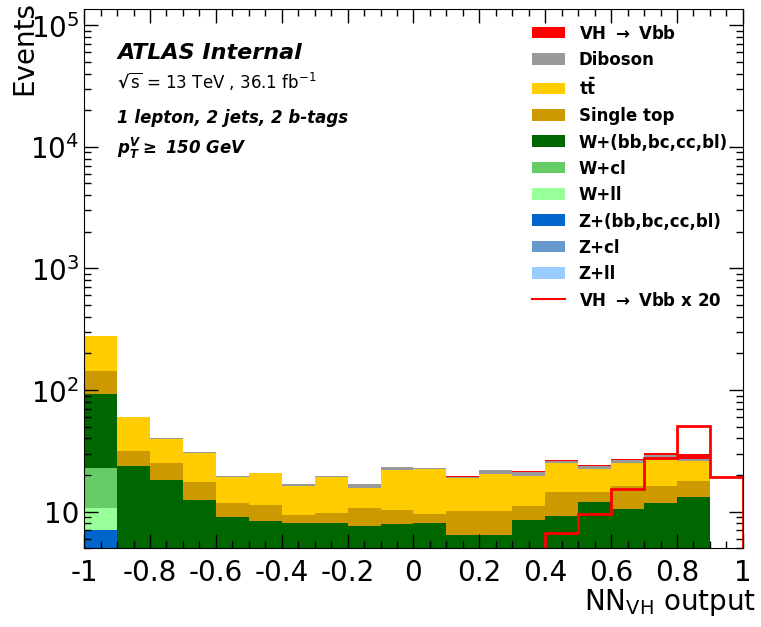

(<Figure size 850x700 with 1 Axes>,
 <Axes: xlabel='NN$_{VH}$ output', ylabel='Events'>)

In [12]:
df_test['decision_value'] = model.predict(dset_test[0])
print("A sensitivity of", round(sensitivity_NN(df_test)[0],2),'was achieved')
nn_output_plot(df_test)

**This material was produced by hackingEducation**  



# Independent work on signal-background separation using machine learning
In this notebook, different configurations and hyperparameters of a neural network classifier are investigated and their performance is evaluated. The objective is to construct a final optimised model, assess its performance, and compare the achieved sensitivity to the cut-based baseline analysis. Note that this is a relatively long notebook, so some variables are defined in multiple places to improve readability and make individual sections easier to follow independently.

The workflow is as follows:


1. A slightly more complex neural network architecture, referred to as classifier2, is defined as a starting point for optimisation.
    
2.  Using classifier2, studies are performed to determine the optimal set of input variables and to investigate the fraction of signal and background training events required for stable and optimal model performance.
    
3. The neural network is optimised sequentially with respect to the following hyperparameters: number of nodes per layer, number of hidden layers, activation function, optimiser, loss function, and training parameters. During this optimisation procedure, the full set of candidate input variables and the full training dataset are used to ensure completeness and to avoid introducing bias. Multiple random seeds are used to account for the stochastic nature of neural network training and to evaluate the stability of the obtained results.
    
4. The full optimisation procedure is repeated three times in order to assess the consistency of the results and quantify possible variations in sensitivity.
    
5. The final optimised model is constructed and trained using the selected hyperparameter configuration, input variable set and training statistics.


The main evaluation metrics used in this analysis are:
- Loss curve: used to assess training stability and convergence behaviour.
- Receiver Operating Characteristic (ROC) curve: used to evaluate the classification performance of the neural network.
- Signal sensitivity : used as the primary metric for comparing the performance of the neural network.





## 1. Initial testing

In this section, a more complex model is introduced to investigate whether increased model complexity can lead to improved sensitivity. The initial model parameters are selected based on functional considerations. The parameters will be examined more thoroughly at a later stage to determine the optimal configuration. For now, the model is primarily used to determine the most informative input variables and to guide subsequent optimisation steps.

In [16]:
# import necessary libraries
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from time import time
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import backend as K

In [17]:
def classifier2(variables):
    """
    NN classifier that predicts whether an event is:
    signal -> output close to 1
    background -> output close to 0
    """
    
    num_variables = len(variables)

    model = Sequential()
    model.add(Input(shape=(num_variables,)))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(16, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(
        loss='binary_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )

    return model



model trained in 14.54s


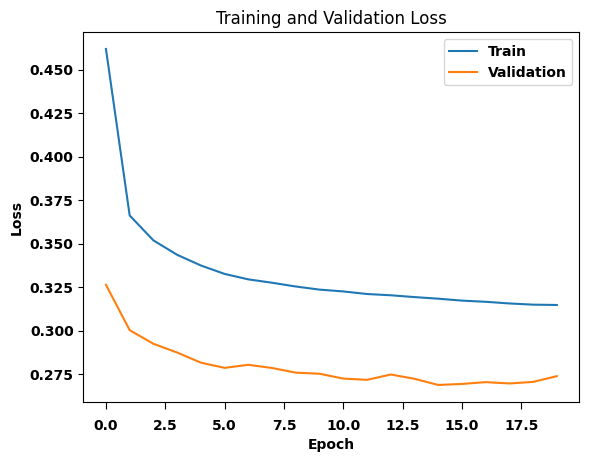

In [18]:
from tensorflow.keras.layers import Input

# Training the model
start = time()

epochs = 20
batchSize = 120

model = classifier2(variables)

history = model.fit(
    x_train,
    y_train,
    sample_weight=w_train,
    validation_data=(dset_val[0], dset_val[1]),
    epochs=epochs,
    batch_size=batchSize,
    verbose=1)

print("model trained in " + str(round(time()-start, 2)) + "s")

# Plot loss
plt.figure()
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend(['Train', 'Validation'])

plt.show()


A sensitivity of 2.34 was achieved


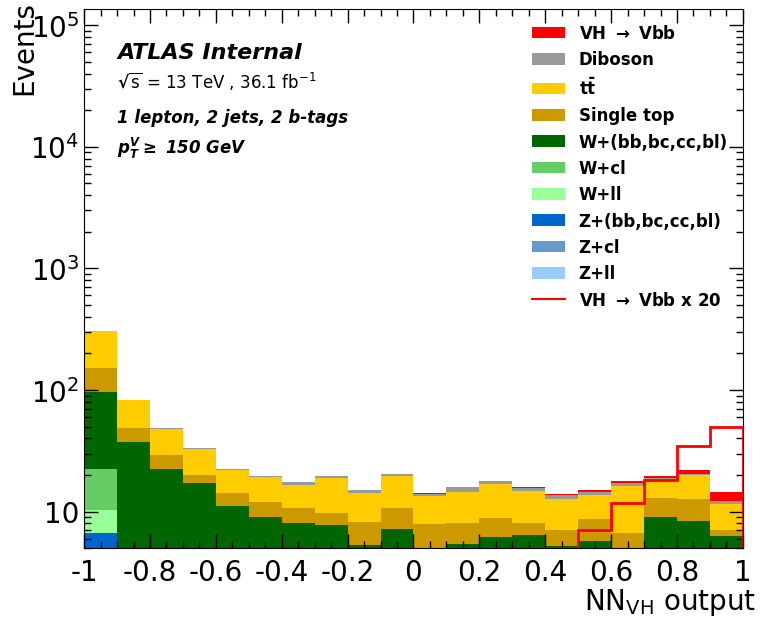

(<Figure size 850x700 with 1 Axes>,
 <Axes: xlabel='NN$_{VH}$ output', ylabel='Events'>)

In [19]:
df_test['decision_value'] = model.predict(dset_test[0])
print("A sensitivity of", round(sensitivity_NN(df_test)[0],2),'was achieved') #apply cut 
nn_output_plot(df_test)

A sensitivity of approximately 2.6 indicates that `classifier2` provides good discrimination between signal and background events, demonstrating that the model is sufficiently effective for further optimisation studies.

### Introduction to the ROC curve
The ROC (Receiver Operating Characteristic) curve illustrates the ability of the neural network to separate signal from background events. Each point on the curve represents a different threshold value applied to the neural network output, determining how many signal and background events are selected.

Signal efficiency is defined as the fraction of signal events correctly classified as signal: signal efficiency = (signal events kept) / (total signal events)

Background efficiency is defined as the fraction of background events incorrectly classified as signal: background efficiency = (background events kept) / (total background events)

Result: the ROC curve demonstrates that the neural network is able to retain a large fraction of signal events while rejecting a significant fraction of background events. An AUC value close to 1 corresponds to excellent discrimination power, confirming that `classifier2` performs well for this dataset.

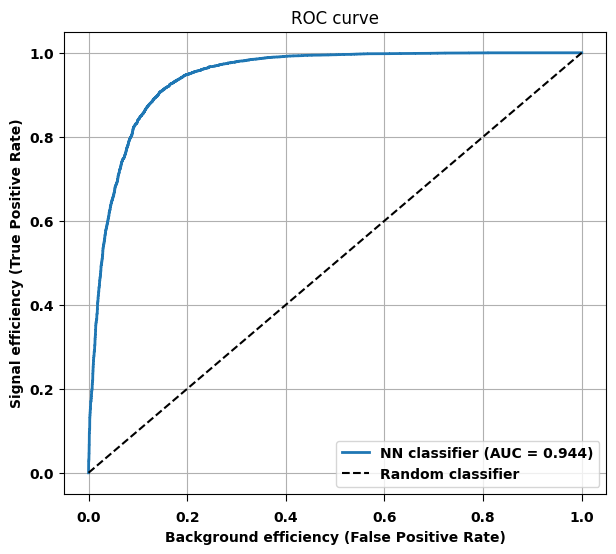

In [22]:
# Get NN predictions for test events
df_test['decision_value'] = model.predict(dset_test[0])

from sklearn.metrics import roc_curve, auc


# True labels from the prepared test dataset
y_true = dset_test[1]

# NN scores already stored in the dataframe
y_score = df_test['decision_value'].values.ravel()

# ROC curve
fpr, tpr, thresholds = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr) #area under curve

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, lw=2, label=f"NN classifier (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')

plt.xlabel("Background efficiency (False Positive Rate)")
plt.ylabel("Signal efficiency (True Positive Rate)")
plt.title("ROC curve")
plt.legend()
plt.grid(True)
plt.show()

In [23]:

# extract important points on the ROC curve
target_signal_eff = [0.9, 0.8, 0.7, 0.6, 0.5]

for eff in target_signal_eff:
    idx = np.argmin(np.abs(tpr - eff))
    print(
        f"Signal efficiency ≈ {tpr[idx]:.3f} | "
        f"Background efficiency ≈ {fpr[idx]:.3f} | "
        f"NN threshold ≈ {thresholds[idx]:.3f}")

Signal efficiency ≈ 0.900 | Background efficiency ≈ 0.141 | NN threshold ≈ 0.654
Signal efficiency ≈ 0.800 | Background efficiency ≈ 0.086 | NN threshold ≈ 0.797
Signal efficiency ≈ 0.700 | Background efficiency ≈ 0.059 | NN threshold ≈ 0.861
Signal efficiency ≈ 0.600 | Background efficiency ≈ 0.039 | NN threshold ≈ 0.900
Signal efficiency ≈ 0.500 | Background efficiency ≈ 0.027 | NN threshold ≈ 0.926


## 2. Training-statistics study: Number of signal and background training events

Two studies are performed to evaluate how the amount of training data affects model performance.

**1. Signal-statistics scan**

All available background training events are used, while only a fraction of the signal training events is included: 10%, 20%, …, 100%. The model is trained for each fraction and the validation sensitivity is evaluated using three different random seeds to account for statistical fluctuations. The scan starts from 10% rather than 0% because both signal and background events are required for the classifier to learn meaningful discrimination.

**2. Background-statistics scan**

The same procedure is repeated for the background sample. All signal training events are used, while only a fraction of the background training events is included (10%, 20%, …, 100%). The model is trained and evaluated in the same way as for the signal scan.

**Interpretation of the results**

If the sensitivity plateaus in the signal-statistics scan, this indicates that increasing the number of signal training events no longer significantly improves performance, suggesting that sufficient signal statistics are already available.

Similarly, if the sensitivity plateaus in the background-statistics scan, this indicates that additional background training events do not substantially improve the classifier performance, implying that the model has sufficient background statistics for effective training.





In [25]:

# Settings
SEED = 42
epochs = 20
batchSize = 120
n_repeats = 3

#fix seed
np.random.seed(SEED)
tf.random.set_seed(SEED)


# Try to identify the label column automatically
possible_label_cols = ["label", "Label", "Class", "class", "signal"]

label_col = None
for col in possible_label_cols:
    if col in df_train.columns:
        label_col = col
        break

if label_col is None:
    raise ValueError("Could not find the label column automatically. ")

print("Using label column:", label_col)

# split full training set into signal and background
df_train_sig = df_train[df_train[label_col] == 1].copy()
df_train_bkg = df_train[df_train[label_col] == 0].copy()

print("Number of full signal training events:", len(df_train_sig))
print("Number of full background training events:", len(df_train_bkg))

Using label column: Class
Number of full signal training events: 50449
Number of full background training events: 26727


In [26]:
def get_val_sensitivity_training_fraction(sig_frac=1.0, bkg_frac=1.0, var_list=None, verbose=0):
    """
    Train classifier2 using only a fraction of signal and background training events.
    Evaluate validation sensitivity.
    Returns mean and std over n_repeats.
    """
    if var_list is None:
        var_list = variables

    val_sensitivities = []

    for i in range(n_repeats):
        K.clear_session() #clears previous models from memory
        seed = SEED + i
        np.random.seed(seed)
        tf.random.set_seed(seed)

        # randomly sample subset of signal and background 
        df_sig_sub = df_train_sig.sample(frac=sig_frac, random_state=seed)
        df_bkg_sub = df_train_bkg.sample(frac=bkg_frac, random_state=seed)

        # combine 
        df_train_sub = pd.concat([df_sig_sub, df_bkg_sub], axis=0)
        # shuffle so that signal and background events are randomly mixed
        df_train_sub = df_train_sub.sample(frac=1.0, random_state=seed).reset_index(drop=True)

        # prepare scaled datasets
        x_train_sub, y_train_sub, w_train_sub, dset_val_sub, dset_test_sub = scale_prepare_data(
            df_train_sub, df_val, df_test, var_list, scaler='standard')

        # build model
        model = classifier2(var_list)

        
        # Stops training automatically if validation loss stops improving
        early_stop = EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True)
        #train model
        model.fit(
            x_train_sub,
            y_train_sub,
            sample_weight=w_train_sub,
            validation_data=(dset_val_sub[0], dset_val_sub[1]),
            epochs=epochs,
            batch_size=batchSize,
            verbose=verbose,
            callbacks=[early_stop])

        # evaluate on validation set
        df_val_tmp = df_val.copy()
        df_val_tmp["decision_value"] = model.predict(dset_val_sub[0], verbose=0).ravel()

        sens = sensitivity_NN(df_val_tmp)[0]
        val_sensitivities.append(sens)

    return np.mean(val_sensitivities), np.std(val_sensitivities)

In [27]:
# Fractions to scan
fractions = [ 0.1,0.2, 0.4,0.6,0.8,0.9, 1.0]

results_stats = []


# 1. Vary signal fraction only
for frac in fractions:
    mean_sens, std_sens = get_val_sensitivity_training_fraction(
        sig_frac=frac,
        bkg_frac=1.0,
        var_list=variables,
        verbose=1)

    results_stats.append({
        "scan_type": "signal_scan",
        "signal_fraction": frac,
        "background_fraction": 1.0,
        "val_sensitivity_mean": mean_sens,
        "val_sensitivity_std": std_sens})


# 2. Vary background fraction only
for frac in fractions:
    mean_sens, std_sens = get_val_sensitivity_training_fraction(
        sig_frac=1.0,
        bkg_frac=frac,
        var_list=variables,
        verbose=1)

    results_stats.append({
        "scan_type": "background_scan",
        "signal_fraction": 1.0,
        "background_fraction": frac,
        "val_sensitivity_mean": mean_sens,
        "val_sensitivity_std": std_sens})

results_stats_df = pd.DataFrame(results_stats)
results_stats_df

,scan_type,signal_fraction,background_fraction,val_sensitivity_mean,val_sensitivity_std
0,signal_scan,0.1,1.0,1.002490,0.010173
1,signal_scan,0.2,1.0,1.067310,0.049035
2,signal_scan,0.4,1.0,1.049600,0.017228
3,signal_scan,0.6,1.0,1.034395,0.016658
4,signal_scan,0.8,1.0,1.053570,0.012472
5,signal_scan,0.9,1.0,1.049362,0.012515
6,signal_scan,1.0,1.0,1.044765,0.024038
7,background_scan,1.0,0.1,0.845757,0.031150
8,background_scan,1.0,0.2,0.936931,0.031636
9,background_scan,1.0,0.4,1.005135,0.021673


In [28]:
# Separate tables
signal_scan_df = results_stats_df[results_stats_df["scan_type"] == "signal_scan"].copy()
background_scan_df = results_stats_df[results_stats_df["scan_type"] == "background_scan"].copy()

print("Signal-statistics scan")
display(signal_scan_df)

print("Background-statistics scan")
display(background_scan_df)

Signal-statistics scan


,scan_type,signal_fraction,background_fraction,val_sensitivity_mean,val_sensitivity_std
0,signal_scan,0.1,1.0,1.002490,0.010173
1,signal_scan,0.2,1.0,1.067310,0.049035
2,signal_scan,0.4,1.0,1.049600,0.017228
3,signal_scan,0.6,1.0,1.034395,0.016658
4,signal_scan,0.8,1.0,1.053570,0.012472
5,signal_scan,0.9,1.0,1.049362,0.012515
6,signal_scan,1.0,1.0,1.044765,0.024038


Background-statistics scan


,scan_type,signal_fraction,background_fraction,val_sensitivity_mean,val_sensitivity_std
7,background_scan,1.0,0.1,0.845757,0.031150
8,background_scan,1.0,0.2,0.936931,0.031636
9,background_scan,1.0,0.4,1.005135,0.021673
10,background_scan,1.0,0.6,1.043926,0.028107
11,background_scan,1.0,0.8,1.036125,0.041705
12,background_scan,1.0,0.9,1.023325,0.042137
13,background_scan,1.0,1.0,1.059494,0.028465


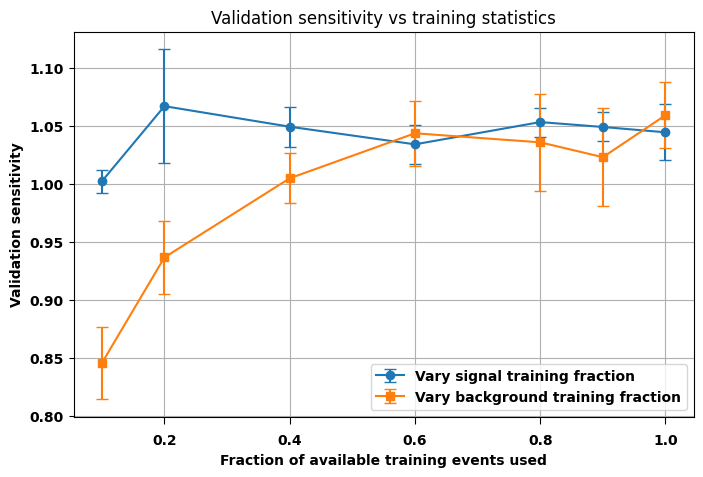

In [29]:
# Plot both scans
plt.figure(figsize=(8,5))

plt.errorbar(
    signal_scan_df["signal_fraction"],
    signal_scan_df["val_sensitivity_mean"],
    yerr=signal_scan_df["val_sensitivity_std"],
    marker='o',
    capsize=4,
    label='Vary signal training fraction')

plt.errorbar(
    background_scan_df["background_fraction"],
    background_scan_df["val_sensitivity_mean"],
    yerr=background_scan_df["val_sensitivity_std"],
    marker='s',
    capsize=4,
    label='Vary background training fraction')

plt.xlabel("Fraction of available training events used")
plt.ylabel("Validation sensitivity")
plt.title("Validation sensitivity vs training statistics")
plt.legend()
plt.grid(True)
plt.show()

Using all available signal events was found to be optimal, as the signal process is rare and the neural network benefits from seeing as many signal examples as possible. On the other hand, the sensitivity was observed to stabilise for background fractions between approximately 0.6 and 1.0, with only marginal improvements beyond this range. Since the computational cost of training is moderate, the full background sample was retained to maximise the available information.

## 3. Input variable study: Sequential backward Feature Elimination (SFE) 
To determine the most relevant input variables, a sequential backward elimination (SBE) procedure is applied.

At each step, one variable is removed from the full input set and the neural network is retrained. The validation sensitivity is then recomputed for each reduced variable set. The variable whose removal leads to the best performance (or the smallest degradation in sensitivity) is considered least important and is permanently removed. The procedure is repeated iteratively on the reduced set of variables.

During the selection stage, multiple temporary neural networks are trained and their validation sensitivities are compared in order to identify the best-performing subset of input variables. After the optimal subset is identified, a neural network is trained using only these selected variables, and the test sensitivity is reported.

**Limitation**

A limitation of this method is that correlations between variables are not fully captured. Two variables may appear individually unimportant if they encode similar information, even though removing both simultaneously could significantly reduce performance.

**Algorithm summary**

- Start with all candidate input variables
- Remove one variable at a time and retrain the neural network
- Compute the validation sensitivity for each reduced set
- Remove the least important variable
- Repeat the procedure on the reduced variable set
- Train the final model using the optimal subset of variables


In [32]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from time import time
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import backend as K
import gc


# Settings

SEED = 42
epochs = 20
batchSize = 120
n_repeats = 3   

np.random.seed(SEED)
tf.random.set_seed(SEED)


# Evaluate sensitivity on validation set
def get_validation_sensitivity(var_list, verbose=0):
    """
    Train model using var_list (chosen subset of variables),
    evaluate sensitivity on df_val.
    Returns mean and std over n_repeats runs.
    """
    val_sensitivities = []
    
    for i in range(n_repeats):
        K.clear_session()
        np.random.seed(SEED + i)
        tf.random.set_seed(SEED + i)

        # rebuild scaled datasets for this variable subset
        x_train_sub, y_train_sub, w_train_sub, dset_val_sub, dset_test_sub = scale_prepare_data(
            df_train, df_val, df_test, var_list, scaler='standard')

        model = classifier2(var_list)

        early_stop = EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True)

        history = model.fit(
            x_train_sub,
            y_train_sub,
            sample_weight=w_train_sub,
            validation_data=(dset_val_sub[0], dset_val_sub[1]),
            epochs=epochs,
            batch_size=batchSize,
            verbose=verbose,
            callbacks=[early_stop])

        # predict NN scores on validation set
        val_scores = model.predict(dset_val_sub[0], verbose=0).ravel()

        # compute sensitivity on validation dataframe
        df_val_tmp = df_val.copy()
        df_val_tmp["decision_value"] = val_scores #store

        sens = sensitivity_NN(df_val_tmp)[0]
        val_sensitivities.append(sens)
        del model #deletes the variable model from memory
        gc.collect() #ensures that memory occupied by the deleted model is freed
    return np.mean(val_sensitivities), np.std(val_sensitivities)


# initialise backward elimination

remaining_vars = variables.copy()
history_rows = []

start_total = time()

# Baseline with all variables
baseline_mean, baseline_std = get_validation_sensitivity(remaining_vars, verbose=0)

history_rows.append({
    "step": 0,
    "n_variables": len(remaining_vars),
    "removed_variable": "NONE",
    "val_sensitivity_mean": baseline_mean,
    "val_sensitivity_std": baseline_std,
    "remaining_variables": remaining_vars.copy()})

print(f"Baseline with all {len(remaining_vars)} variables: {baseline_mean:.3f} ± {baseline_std:.3f}")

step = 1

#elimination loop start
while len(remaining_vars) > 1:
    print(f"Step {step}")
    print("Current variables:", remaining_vars)

    trial_results = []
    
    #test removing each variable
    for var in remaining_vars:
        candidate_vars = [v for v in remaining_vars if v != var]
        
        mean_sens, std_sens = get_validation_sensitivity(candidate_vars, verbose=0)
        # store all trial results
        trial_results.append({
            "removed_variable": var,
            "candidate_variables": candidate_vars,
            "val_sensitivity_mean": mean_sens,
            "val_sensitivity_std": std_sens})

        print(f"Remove {var:15s} -> val sensitivity = {mean_sens:.3f} ± {std_sens:.3f}")

    # choose variable whose removal gives the best validation sensitivity
    best_trial = max(trial_results, key=lambda x: x["val_sensitivity_mean"])
    # remove that variable
    removed_now = best_trial["removed_variable"]
    remaining_vars = best_trial["candidate_variables"]
    #store result of the removed variable, best subset and corresponding sensitivity at this step
    history_rows.append({
        "step": step,
        "n_variables": len(remaining_vars),
        "removed_variable": removed_now,
        "val_sensitivity_mean": best_trial["val_sensitivity_mean"],
        "val_sensitivity_std": best_trial["val_sensitivity_std"],
        "remaining_variables": remaining_vars.copy()})

    print(f"\nRemoved permanently: {removed_now}")
    print(f"New subset: {remaining_vars}")
    print(f"Best validation sensitivity now: {best_trial['val_sensitivity_mean']:.3f} ± {best_trial['val_sensitivity_std']:.3f}")

    step += 1
    
#table showing the full elimination history
history_df = pd.DataFrame(history_rows)

print("\nFinished in", round(time() - start_total, 2), "s")
display(history_df[["step", "n_variables", "removed_variable", "val_sensitivity_mean", "val_sensitivity_std"]])

Baseline with all 14 variables: 1.058 ± 0.015
Step 1
Current variables: ['nJ', 'nTags', 'dRBB', 'pTB1', 'pTB2', 'pTV', 'Mtop', 'mTW', 'MET', 'dYWH', 'dPhiVBB', 'MV1cB1_cont', 'MV1cB2_cont', 'nTrackJetsOR']
Remove nJ              -> val sensitivity = 1.023 ± 0.015
Remove nTags           -> val sensitivity = 1.046 ± 0.006
Remove dRBB            -> val sensitivity = 0.661 ± 0.003
Remove pTB1            -> val sensitivity = 1.034 ± 0.028
Remove pTB2            -> val sensitivity = 1.039 ± 0.027
Remove pTV             -> val sensitivity = 1.041 ± 0.021
Remove Mtop            -> val sensitivity = 1.052 ± 0.033
Remove mTW             -> val sensitivity = 1.052 ± 0.003
Remove MET             -> val sensitivity = 0.995 ± 0.023
Remove dYWH            -> val sensitivity = 1.015 ± 0.028
Remove dPhiVBB         -> val sensitivity = 1.052 ± 0.010
Remove MV1cB1_cont     -> val sensitivity = 1.013 ± 0.010
Remove MV1cB2_cont     -> val sensitivity = 1.027 ± 0.021
Remove nTrackJetsOR    -> val sensitivit

,step,n_variables,removed_variable,val_sensitivity_mean,val_sensitivity_std
0,0,14,NONE,1.058125,0.014673
1,1,13,nTrackJetsOR,1.053387,0.032921
2,2,12,mTW,1.071460,0.014471
3,3,11,dYWH,1.079270,0.018377
4,4,10,dPhiVBB,1.064055,0.034001
5,5,9,MV1cB2_cont,1.058073,0.043287
6,6,8,pTB2,1.027936,0.027185
7,7,7,nTags,1.012241,0.024513
8,8,6,nJ,1.029397,0.007526
9,9,5,MET,0.976298,0.008602


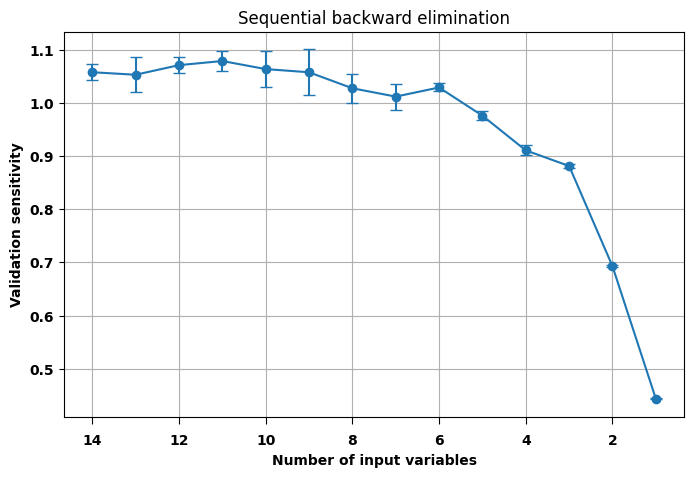

In [33]:
# plot validation sensitivity vs number of inputs
plt.figure(figsize=(8,5))
plt.errorbar(
    history_df["n_variables"],
    history_df["val_sensitivity_mean"],
    yerr=history_df["val_sensitivity_std"],
    marker="o",
    capsize=4)
plt.gca().invert_xaxis()
plt.xlabel("Number of input variables")
plt.ylabel("Validation sensitivity")
plt.title("Sequential backward elimination")
plt.grid(True)
plt.show()

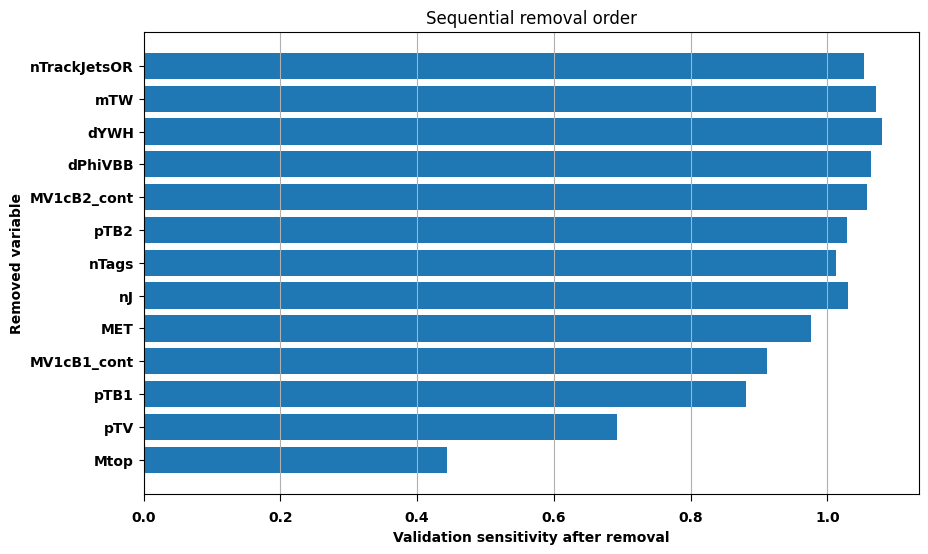

In [34]:
# plot how the removed variable affects validation sens
plot_df = history_df[history_df["step"] > 0].copy()

plt.figure(figsize=(10,6))
plt.barh(plot_df["removed_variable"], plot_df["val_sensitivity_mean"])
plt.xlabel("Validation sensitivity after removal")
plt.ylabel("Removed variable")
plt.title("Sequential removal order")
plt.gca().invert_yaxis()
plt.grid(axis="x")
plt.show()

In [35]:
# extract the best results
best_idx = history_df["val_sensitivity_mean"].idxmax()
best_row = history_df.loc[best_idx]

best_variables = best_row["remaining_variables"]

print("Best subset found at step:", best_row["step"])
print("Number of variables:", best_row["n_variables"])
print("Best validation sensitivity:", round(best_row["val_sensitivity_mean"], 3))
print("Best variables:")
print(best_variables)

Best subset found at step: 3
Number of variables: 11
Best validation sensitivity: 1.079
Best variables:
['nJ', 'nTags', 'dRBB', 'pTB1', 'pTB2', 'pTV', 'Mtop', 'MET', 'dPhiVBB', 'MV1cB1_cont', 'MV1cB2_cont']


Final test sensitivity: 2.737


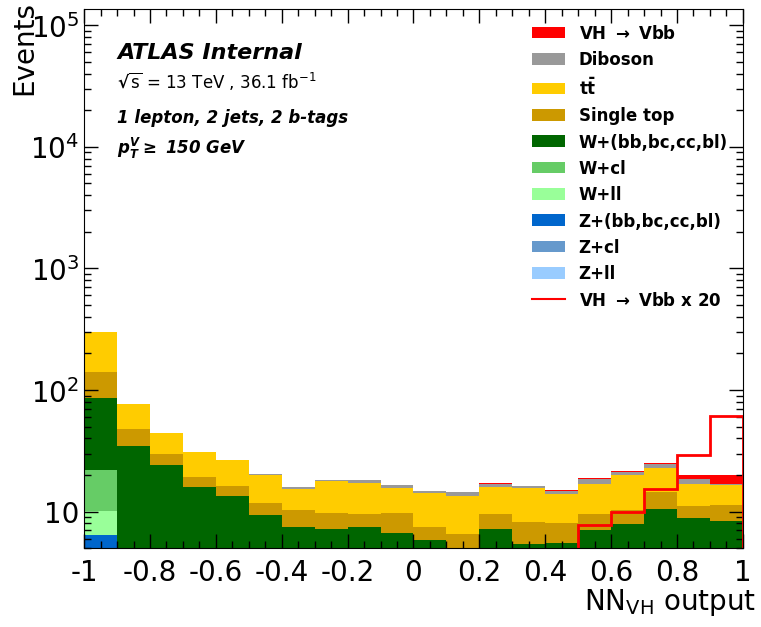

(<Figure size 850x700 with 1 Axes>,
 <Axes: xlabel='NN$_{VH}$ output', ylabel='Events'>)

In [36]:
# prepare datasets using best subset
x_train_best, y_train_best, w_train_best, dset_val_best, dset_test_best = scale_prepare_data(
    df_train, df_val, df_test, best_variables, scaler='standard')

# train a final model using the best subset
final_model = classifier2(best_variables)


history_final = final_model.fit(
    x_train_best,
    y_train_best,
    sample_weight=w_train_best,
    validation_data=(dset_val_best[0], dset_val_best[1]),
    epochs=epochs,
    batch_size=batchSize,
    verbose=1,)

# evaluate on test set 
df_test_final = df_test.copy()
df_test_final["decision_value"] = final_model.predict(dset_test_best[0], verbose=0).ravel()
print("Final test sensitivity:", round(sensitivity_NN(df_test_final)[0], 3))
nn_output_plot(df_test_final)

The final test sensitivity is approximately 2.6 after optimising the set of input variables, indicating that the selected variable subset provides good discriminating power.

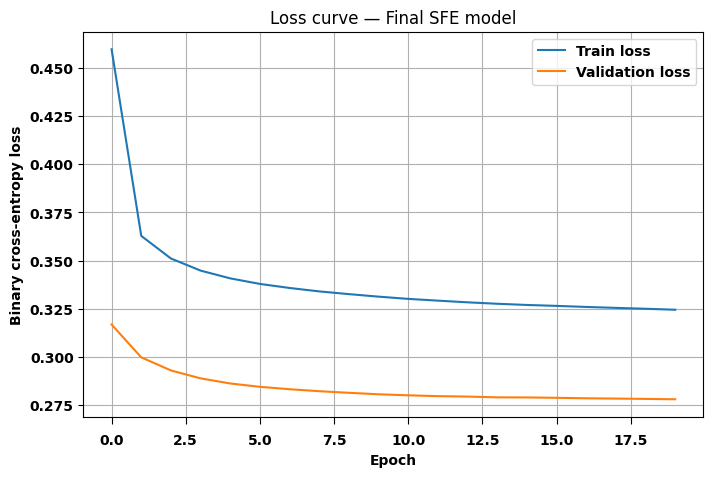

In [38]:
# plot loss

plt.figure(figsize=(8,5))
plt.plot(history_final.history['loss'], label='Train loss')
plt.plot(history_final.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy loss')
plt.title('Loss curve — Final SFE model')
plt.legend()
plt.grid(True)
plt.show()

The loss curve shows that both the training and validation loss decrease steadily and then stabilize, indicating that the model is learning effectively and converging to a good solution. Since the two curves follow a similar trend without diverging, there is no clear sign of overfitting, suggesting that the model generalises well to unseen data. The rapid decrease during the first few epochs reflects the model learning the main patterns in the data, while the later flattening indicates smaller adjustments as the model fine-tunes its parameters. The training loss being slightly higher than the validation loss can occur when the training sample contains more complex or noisier events. The smooth stabilisation of the validation loss also shows that early stopping is working as intended, stopping training close to the optimal point before overfitting begins. Overall, this behaviour suggests that the SFE-optimised model is stable, well-trained, and appropriately complex for this task.

## 4. Optimisation of the number of nodes per layer

In this step, the goal is to determine the optimal number of nodes in each hidden layer when constructing the neural network classifier. The model is trained using `df_train`, while `df_val` is used to evaluate the validation sensitivity during the optimisation procedure. The input variables used for training have been previously scaled. At this stage, a neural network with three hidden layers is used, while the remaining hyperparameters are kept the same as in `classifier2`. These hyperparameters will be optimised in later steps, allowing the effect of the number of nodes per layer to be studied independently.

The validation sensitivity of different configurations is compared. The node configuration that yields the highest validation sensitivity is selected as the optimal choice.

Finally, the neural network is retrained using this optimal architecture, and its performance is evaluated on the test dataset `df_test`.

In [41]:
# Use all variables
variables = ["nJ",
    "nTags",
    "dRBB",
    "pTB1",
    "pTB2",
    "pTV",
    "Mtop",
    "mTW",
    "MET",
    "dYWH",
    "dPhiVBB",
    "MV1cB1_cont",
    "MV1cB2_cont",
    "nTrackJetsOR"]


In [42]:

def classifier_nodes(variables, n1, n2, n3):
    """
    NN classifier where number of nodes in each hidden layer
    can be changaed
    """
    num_variables = len(variables)

    model = Sequential()
    model.add(Input(shape=(num_variables,)))
    model.add(Dense(n1, activation='relu'))
    model.add(Dense(n2, activation='relu'))
    model.add(Dense(n3, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    
    model.compile(
        loss='binary_crossentropy',
        optimizer='adam',
        metrics=['accuracy'])

    return model

In [43]:

def get_val_sensitivity_nodes_avg(n1, n2, n3, epochs=30, batchSize=120, n_repeats=3):
    """ 
    Evaluates how good a specific NN architecture is (n1,n2,n3)
    3 random seeds
    
    returns:
    mean sens, std sens
    """
    sensitivities = []
    models = []

    for i in range(n_repeats):
        np.random.seed(42 + i)
        tf.random.set_seed(42 + i)
        
        #train model for each node configuration
        model = classifier_nodes(variables, n1, n2, n3)

        early_stop = EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True)

        model.fit(
            x_train,
            y_train,
            sample_weight=w_train,
            validation_data=(dset_val[0], dset_val[1]),
            epochs=epochs,
            batch_size=batchSize,
            verbose=0,
            callbacks=[early_stop])

        df_val_tmp = df_val.copy()
        df_val_tmp["decision_value"] = model.predict(dset_val[0], verbose=0).ravel()
        #evaluate sens on validation set
        sens = sensitivity_NN(df_val_tmp)[0]
        sensitivities.append(sens)
        models.append(model)

    mean_sens = np.mean(sensitivities)
    std_sens = np.std(sensitivities)



    return mean_sens, std_sens

In [44]:
node_configs = [
    (8, 4, 2),
    (16, 8, 4),
    (24, 12, 6),
    (32, 16, 8),
    (48, 24, 12),
    (64, 32, 16),
    (96, 48, 24),
    (128, 64, 32)]


results = []

best_mean_sens = -999 #very low starting value so that the first real sensitivity result will always be larger
best_std_sens = None
best_config = None

#loop over different configurations
for n1, n2, n3 in node_configs:
    mean_sens, std_sens = get_val_sensitivity_nodes_avg(
        n1, n2, n3,
        epochs=30,
        batchSize=120,
        n_repeats=3)

    results.append((n1, n2, n3, mean_sens, std_sens))

    print(f"Nodes ({n1}, {n2}, {n3}) -> validation sensitivity = {mean_sens:.3f} ± {std_sens:.3f}")

    #if this architecture is better than all previous, then store it as the new best
    if mean_sens > best_mean_sens:
        best_mean_sens = mean_sens
        best_std_sens = std_sens
        best_config = (n1, n2, n3)


Nodes (8, 4, 2) -> validation sensitivity = 0.994 ± 0.063
Nodes (16, 8, 4) -> validation sensitivity = 1.016 ± 0.012
Nodes (24, 12, 6) -> validation sensitivity = 1.041 ± 0.023
Nodes (32, 16, 8) -> validation sensitivity = 1.047 ± 0.017
Nodes (48, 24, 12) -> validation sensitivity = 1.056 ± 0.009
Nodes (64, 32, 16) -> validation sensitivity = 1.035 ± 0.021
Nodes (96, 48, 24) -> validation sensitivity = 1.056 ± 0.021
Nodes (128, 64, 32) -> validation sensitivity = 1.044 ± 0.024


In [45]:
# show in table
results_df = pd.DataFrame(
    results,
    columns=["nodes_layer1", "nodes_layer2", "nodes_layer3", "val_sensitivity_mean", "val_sensitivity_std"])

display(results_df)

,nodes_layer1,nodes_layer2,nodes_layer3,val_sensitivity_mean,val_sensitivity_std
0,8,4,2,0.993684,0.062718
1,16,8,4,1.015592,0.012240
2,24,12,6,1.041452,0.023490
3,32,16,8,1.047074,0.017442
4,48,24,12,1.055696,0.008664
5,64,32,16,1.035417,0.020585
6,96,48,24,1.056250,0.020719
7,128,64,32,1.044243,0.023988


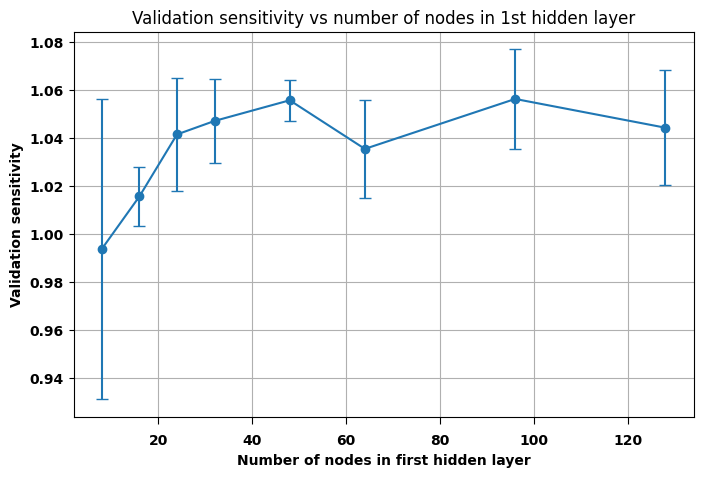

In [46]:
# plot validation sens vs number of nodes in 1st hidden layer

plt.figure(figsize=(8,5))
plt.errorbar(
    results_df["nodes_layer1"],
    results_df["val_sensitivity_mean"],
    yerr=results_df["val_sensitivity_std"],
    marker='o',
    capsize=4)
plt.xlabel("Number of nodes in first hidden layer")
plt.ylabel("Validation sensitivity")
plt.title("Validation sensitivity vs number of nodes in 1st hidden layer")
plt.grid(True)
plt.show()

In [47]:
# extract info
print("Best validation sensitivity:", round(best_mean_sens, 3))
print("Validation sensitivity spread:", round(best_std_sens, 3))
print("Best node configuration:", best_config)


Best validation sensitivity: 1.056
Validation sensitivity spread: 0.021
Best node configuration: (96, 48, 24)


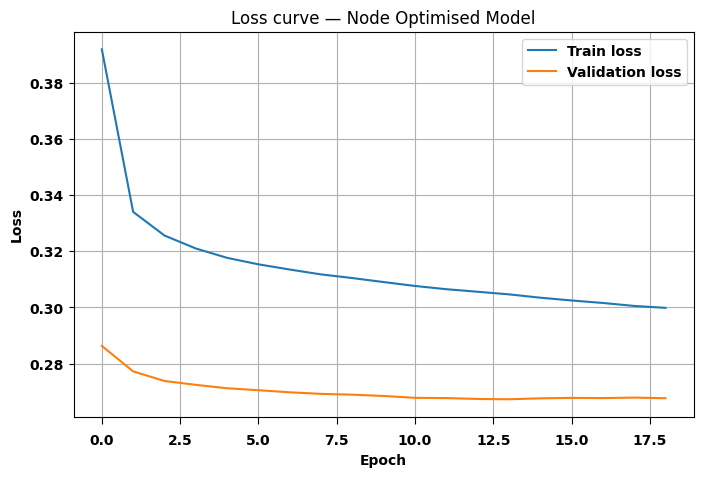

In [48]:
n1, n2, n3 = best_config

model_nodes = classifier_nodes(variables, n1, n2, n3)


# train final model with best nodes configurations

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True)

history_nodes = model_nodes.fit(
    x_train,
    y_train,
    sample_weight=w_train,
    validation_data=(dset_val[0], dset_val[1]),
    epochs=50,
    batch_size=120,
    verbose=1,
    callbacks=[early_stop])

# loss curve 
plt.figure(figsize=(8,5))
plt.plot(history_nodes.history['loss'], label='Train loss')
plt.plot(history_nodes.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss curve — Node Optimised Model')
plt.legend()
plt.grid(True)
plt.show()


Final test sensitivity for best node configuration: 2.382


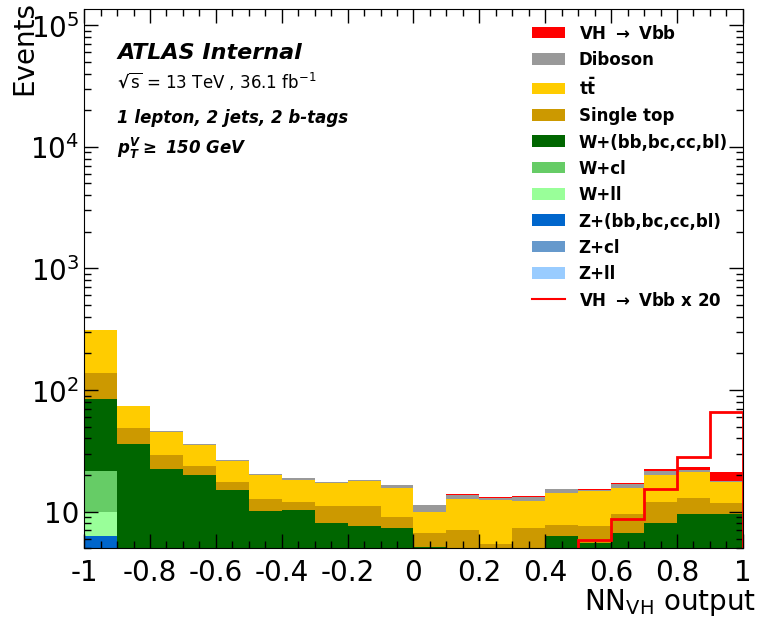

(<Figure size 850x700 with 1 Axes>,
 <Axes: xlabel='NN$_{VH}$ output', ylabel='Events'>)

In [49]:
#evaluate model on test set 
df_test_nodes = df_test.copy()
df_test_nodes["decision_value"] = model_nodes.predict(dset_test[0], verbose=0).ravel()

test_sens_nodes = sensitivity_NN(df_test_nodes)[0]

print("Final test sensitivity for best node configuration:", round(test_sens_nodes, 3))
nn_output_plot(df_test_nodes)

The optimal node configuration achieves a sensitivity of approximately 2.7, indicating good performance. This suggests that the chosen architecture is suitable and provides a strong basis for further optimisation steps.

## 5. Optimal number of hidden layers
In this section, the goal is to determine the optimal number of hidden layers. The previously identified optimal node configuration is used, while the remaining hyperparameters are again kept the same as in `classifier2`. 

In [52]:
print("Best node configuration from previous section:", best_config)
n1_best, n2_best, n3_best = best_config
#use the optimal node configuration (fixed) to find the optimal number of hidden layers.

Best node configuration from previous section: (96, 48, 24)


In [53]:

def classifier_hidden_layers_bestconfig(variables, n_hidden_layers, best_config):
    """
    NN classifier where number of hidden layers can be chosen
    """
    num_variables = len(variables)
    n1, n2, n3 = best_config

    model = Sequential()
    model.add(Input(shape=(num_variables,)))
    
    #Add hidden layers depending on requested depth
    if n_hidden_layers >= 1:
        model.add(Dense(n1, activation='relu'))
    if n_hidden_layers >= 2:
        model.add(Dense(n2, activation='relu'))
    if n_hidden_layers >= 3:
        model.add(Dense(n3, activation='relu'))

    model.add(Dense(1, activation='sigmoid'))
    #same setting as before (most reasonable one)
    model.compile(
        loss='binary_crossentropy',
        optimizer='adam',
        metrics=['accuracy'])

    return model

In [54]:
def get_val_sensitivity_hidden_layers_bestconfig(n_hidden_layers, best_config, epochs=30, batchSize=120, n_repeats=3):
    """
    Evaluate sensitvity obtained from NN with different hidden layers
    3 seeds
    returns: mean sens and std sens
    """

    sensitivities = []
    models = []

    for i in range(n_repeats):
        K.clear_session()
        np.random.seed(42 + i)
        tf.random.set_seed(42 + i)

        #build model
        model = classifier_hidden_layers_bestconfig(
            variables,
            n_hidden_layers=n_hidden_layers,
            best_config=best_config)

        early_stop = EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True)

        #train model
        model.fit(
            x_train,
            y_train,
            sample_weight=w_train,
            validation_data=(dset_val[0], dset_val[1]),
            epochs=epochs,
            batch_size=batchSize,
            verbose=0,
            callbacks=[early_stop])
        # predict for validation set
        df_val_tmp = df_val.copy()
        df_val_tmp["decision_value"] = model.predict(dset_val[0], verbose=0).ravel()

        sens = sensitivity_NN(df_val_tmp)[0]
        sensitivities.append(sens)
        models.append(model)

    mean_sens = np.mean(sensitivities)
    std_sens = np.std(sensitivities)
   

    
    return mean_sens, std_sens

In [55]:
hidden_layer_options = [1, 2, 3]

results_layers = [] #store performance of each architecture

best_mean_sens_layers = -999
best_std_sens_layers = None
best_n_hidden_layers = None

#loop over possible number of hidden layers
for n_hidden in hidden_layer_options:
    mean_sens, std_sens = get_val_sensitivity_hidden_layers_bestconfig(
        n_hidden_layers=n_hidden,
        best_config=best_config,
        epochs=30,
        batchSize=120,
        n_repeats=3)

    results_layers.append((n_hidden, mean_sens, std_sens))

    print(f"{n_hidden} hidden layers using best_config {best_config} -> validation sensitivity = {mean_sens:.3f} ± {std_sens:.3f}")

    # update stored best values
    if mean_sens > best_mean_sens_layers:
        best_mean_sens_layers = mean_sens
        best_std_sens_layers = std_sens
        best_n_hidden_layers = n_hidden


1 hidden layers using best_config (96, 48, 24) -> validation sensitivity = 1.053 ± 0.041
2 hidden layers using best_config (96, 48, 24) -> validation sensitivity = 1.051 ± 0.005
3 hidden layers using best_config (96, 48, 24) -> validation sensitivity = 1.038 ± 0.018


In [56]:
# show in table
results_layers_df = pd.DataFrame(
    results_layers,
    columns=["n_hidden_layers", "val_sensitivity_mean", "val_sensitivity_std"])

display(results_layers_df)



,n_hidden_layers,val_sensitivity_mean,val_sensitivity_std
0,1,1.052753,0.041141
1,2,1.050655,0.005312
2,3,1.038178,0.017655


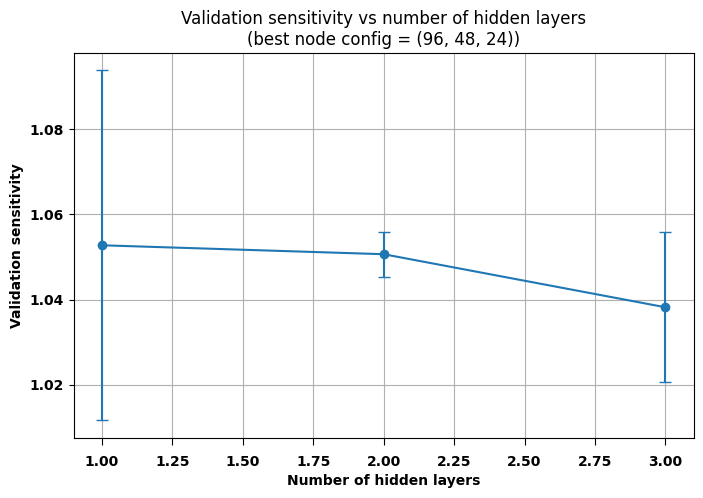

Best node configuration used: (96, 48, 24)
Best validation sensitivity: 1.053
Validation sensitivity spread: 0.041
Best number of hidden layers: 1


In [57]:
# plot validation sens vs number of hidden layers
plt.figure(figsize=(8,5))
plt.errorbar(
    results_layers_df["n_hidden_layers"],
    results_layers_df["val_sensitivity_mean"],
    yerr=results_layers_df["val_sensitivity_std"],
    marker='o',
    capsize=4)
plt.xlabel("Number of hidden layers")
plt.ylabel("Validation sensitivity")
plt.title(f"Validation sensitivity vs number of hidden layers\n(best node config = {best_config})")
plt.grid(True)
plt.show()

print("Best node configuration used:", best_config)
print("Best validation sensitivity:", round(best_mean_sens_layers, 3))
print("Validation sensitivity spread:", round(best_std_sens_layers, 3))
print("Best number of hidden layers:", best_n_hidden_layers)

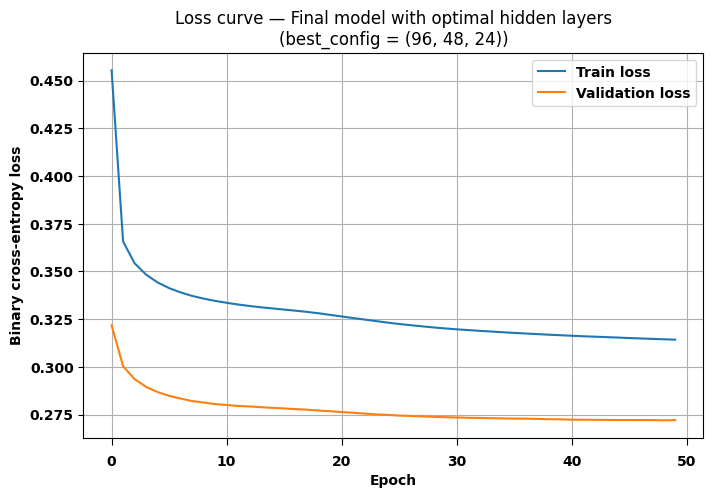

In [58]:
# build and train a final model 

final_model_layers = classifier_hidden_layers_bestconfig(
    variables,
    n_hidden_layers=best_n_hidden_layers,
    best_config=best_config)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True)

history_layers = final_model_layers.fit(
    x_train,
    y_train,
    sample_weight=w_train,
    validation_data=(dset_val[0], dset_val[1]),
    epochs=50,
    batch_size=120,
    verbose=1,
    callbacks=[early_stop])

#plot loss
plt.figure(figsize=(8,5))
plt.plot(history_layers.history['loss'], label='Train loss')
plt.plot(history_layers.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy loss')
plt.title(f'Loss curve — Final model with optimal hidden layers\n(best_config = {best_config})')
plt.legend()
plt.grid(True)
plt.show()

Final test sensitivity for optimal hidden-layer model: 2.496


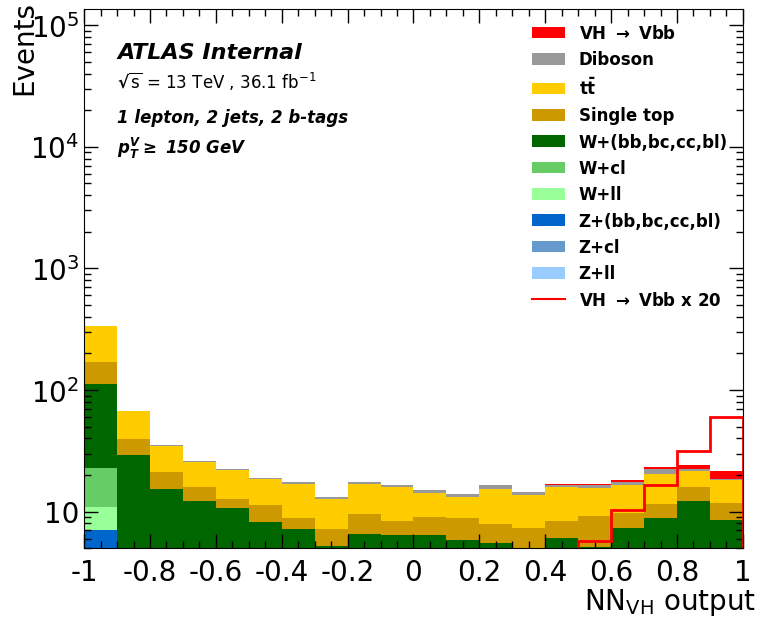

(<Figure size 850x700 with 1 Axes>,
 <Axes: xlabel='NN$_{VH}$ output', ylabel='Events'>)

In [59]:
#compute test sensitivity after finding best result
df_test_layers = df_test.copy()
df_test_layers["decision_value"] = final_model_layers.predict(dset_test[0], verbose=0).ravel()

test_sens_layers = sensitivity_NN(df_test_layers)[0]

print("Final test sensitivity for optimal hidden-layer model:", round(test_sens_layers, 3))
nn_output_plot(df_test_layers)

The optimal hidden-layer configuration achieves a sensitivity of approximately 2.6, which is a reasonable result and indicates that the model complexity is appropriate for this problem.

## 6. Optimal activation function

In [62]:
# best architecture so far
print("Best node configuration:", best_config)
print("Best number of hidden layers:", best_n_hidden_layers)

Best node configuration: (96, 48, 24)
Best number of hidden layers: 1


In [63]:
def classifier_activation_scan(variables, best_config, best_n_hidden_layers, activation_name):
    """
    Classifier where activation function can be chosen 
    """
    num_variables = len(variables)
    n1, n2, n3 = best_config

    model = Sequential()
    model.add(Input(shape=(num_variables,)))

    if best_n_hidden_layers >= 1:
        model.add(Dense(n1, activation=activation_name))
    if best_n_hidden_layers >= 2:
        model.add(Dense(n2, activation=activation_name))
    if best_n_hidden_layers >= 3:
        model.add(Dense(n3, activation=activation_name))

    model.add(Dense(1, activation='sigmoid'))
    
    #keep as before (for now)
    model.compile(
        loss='binary_crossentropy',
        optimizer='adam',
        metrics=['accuracy'])

    return model

In [64]:
def get_val_sensitivity_activation(activation_name, epochs=30, batchSize=120, n_repeats=3):
    """
    Evaluate sensitvity obtained from NN with different activation function
    """
    sensitivities = []
    models = []

    for i in range(n_repeats):
        K.clear_session()
        np.random.seed(42 + i)
        tf.random.set_seed(42 + i)

        model = classifier_activation_scan(
            variables=variables,
            best_config=best_config,
            best_n_hidden_layers=best_n_hidden_layers,
            activation_name=activation_name)

        early_stop = EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True)

        model.fit(
            x_train,
            y_train,
            sample_weight=w_train,
            validation_data=(dset_val[0], dset_val[1]),
            epochs=epochs,
            batch_size=batchSize,
            verbose=0,
            callbacks=[early_stop])

        df_val_tmp = df_val.copy()
        df_val_tmp["decision_value"] = model.predict(dset_val[0], verbose=0).ravel()

        sens = sensitivity_NN(df_val_tmp)[0]
        sensitivities.append(sens)
        models.append(model)

    mean_sens = np.mean(sensitivities)
    std_sens = np.std(sensitivities)

    

    return mean_sens, std_sens

In [65]:
activation_options = ["relu", "tanh", "elu", "selu"]

results_activation = []

best_mean_sens_activation = -999
best_std_sens_activation = None
best_activation = None


# loop over different activation functions
for act in activation_options:
    mean_sens, std_sens = get_val_sensitivity_activation(
        activation_name=act,
        epochs=30,
        batchSize=120,
        n_repeats=3)

    results_activation.append((act, mean_sens, std_sens))

    print(f"Activation = {act} -> validation sensitivity = {mean_sens:.3f} ± {std_sens:.3f}")
    
    #update
    if mean_sens > best_mean_sens_activation:
        best_mean_sens_activation = mean_sens
        best_std_sens_activation = std_sens
        best_activation = act
        

Activation = relu -> validation sensitivity = 1.031 ± 0.018
Activation = tanh -> validation sensitivity = 1.005 ± 0.010
Activation = elu -> validation sensitivity = 0.986 ± 0.015
Activation = selu -> validation sensitivity = 1.011 ± 0.005


In [66]:
# show in table
results_activation_df = pd.DataFrame(
    results_activation,
    columns=["activation_function", "val_sensitivity_mean", "val_sensitivity_std"])

display(results_activation_df)

,activation_function,val_sensitivity_mean,val_sensitivity_std
0,relu,1.031273,0.017546
1,tanh,1.005036,0.010466
2,elu,0.985511,0.015268
3,selu,1.010830,0.005031


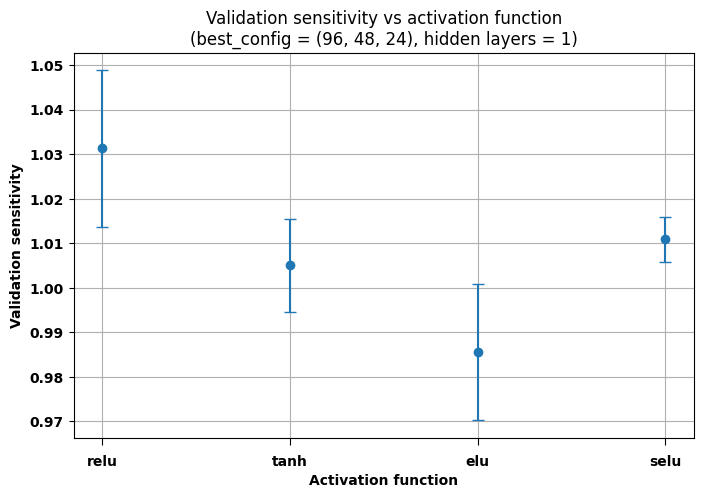

In [67]:
# plot val sens vs activation function
plt.figure(figsize=(8,5))
plt.errorbar(
    results_activation_df["activation_function"],
    results_activation_df["val_sensitivity_mean"],
    yerr=results_activation_df["val_sensitivity_std"],
    fmt='o',
    capsize=4)
plt.xlabel("Activation function")
plt.ylabel("Validation sensitivity")
plt.title(f"Validation sensitivity vs activation function\n(best_config = {best_config}, hidden layers = {best_n_hidden_layers})")
plt.grid(True)
plt.show()

In [68]:
# extract info
print("Best node configuration used:", best_config)
print("Best number of hidden layers used:", best_n_hidden_layers)
print("Best validation sensitivity:", round(best_mean_sens_activation, 3))
print("Validation sensitivity spread:", round(best_std_sens_activation, 3))
print("Best activation function:", best_activation)

Best node configuration used: (96, 48, 24)
Best number of hidden layers used: 1
Best validation sensitivity: 1.031
Validation sensitivity spread: 0.018
Best activation function: relu


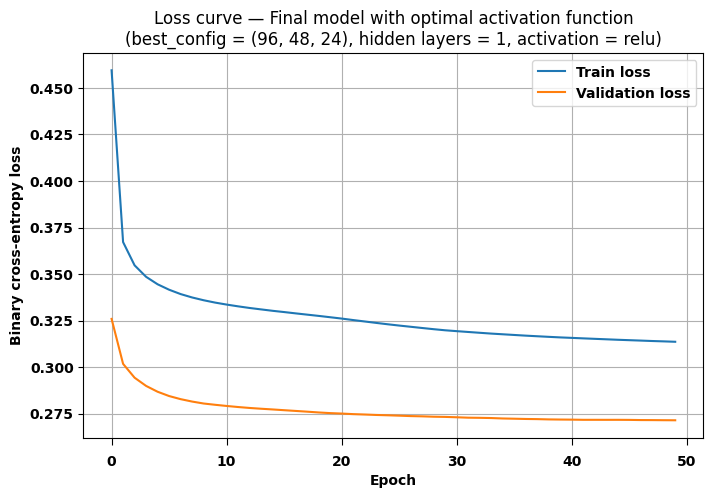

In [69]:
#build and train final model
final_model_activation = classifier_activation_scan(
    variables=variables,
    best_config=best_config,
    best_n_hidden_layers=best_n_hidden_layers,
    activation_name=best_activation)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True)

history_activation = final_model_activation.fit(
    x_train,
    y_train,
    sample_weight=w_train,
    validation_data=(dset_val[0], dset_val[1]),
    epochs=50,
    batch_size=120,
    verbose=1,
    callbacks=[early_stop])

# plot loss
plt.figure(figsize=(8,5))
plt.plot(history_activation.history['loss'], label='Train loss')
plt.plot(history_activation.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy loss')
plt.title(f'Loss curve — Final model with optimal activation function\n(best_config = {best_config}, hidden layers = {best_n_hidden_layers}, activation = {best_activation})')
plt.legend()
plt.grid(True)
plt.show()

Final test sensitivity for optimal activation-function model: 2.529


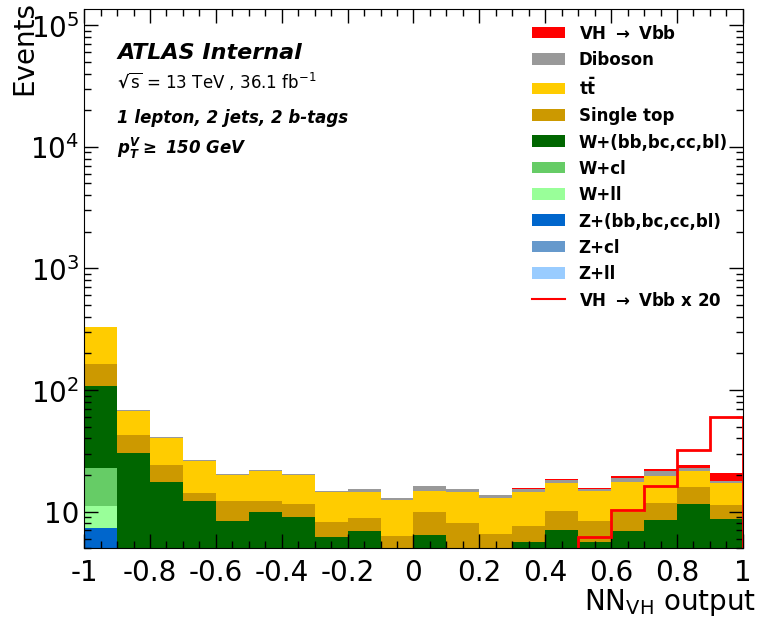

(<Figure size 850x700 with 1 Axes>,
 <Axes: xlabel='NN$_{VH}$ output', ylabel='Events'>)

In [70]:
#compute sensitivity after optimising
df_test_activation = df_test.copy()
df_test_activation["decision_value"] = final_model_activation.predict(dset_test[0], verbose=0).ravel()

test_sens_activation = sensitivity_NN(df_test_activation)[0]

print("Final test sensitivity for optimal activation-function model:", round(test_sens_activation, 3))
nn_output_plot(df_test_activation)

The optimal activation function model along with all previous optimised results achieves a sensitivity of approximately 2.7, which is a reasonable result.

## 7. Optimisation algorithm

In [73]:
# optimised settings so far 
print("Best node configuration:", best_config)
print("Best number of hidden layers:", best_n_hidden_layers)
print("Best activation function:", best_activation)

Best node configuration: (96, 48, 24)
Best number of hidden layers: 1
Best activation function: relu


In [74]:
def classifier_optimizer_scan(variables, best_config, best_n_hidden_layers, best_activation, optimizer_obj):
    num_variables = len(variables)
    n1, n2, n3 = best_config
    """
    classifier where optimisation algorithm can be chosen
    """
    model = Sequential()
    model.add(Input(shape=(num_variables,)))

    if best_n_hidden_layers >= 1:
        model.add(Dense(n1, activation=best_activation))
    if best_n_hidden_layers >= 2:
        model.add(Dense(n2, activation=best_activation))
    if best_n_hidden_layers >= 3:
        model.add(Dense(n3, activation=best_activation))

    model.add(Dense(1, activation='sigmoid'))

    model.compile(
        loss='binary_crossentropy',
        optimizer=optimizer_obj,
        metrics=['accuracy'])

    return model

In [75]:
def get_val_sensitivity_optimizer(optimizer_name, epochs=30, batchSize=120, n_repeats=3):
    """
    evaluate the sensitivity when model is trained on different optimisation algorithms
    """
    
    sensitivities = []

    for i in range(n_repeats):
        K.clear_session()
        np.random.seed(42 + i)
        tf.random.set_seed(42 + i)
        
        # Map optimiser name to the corresponding optimiser used for training.
        if optimizer_name == "adam":
            optimizer_obj = Adam()
        elif optimizer_name == "sgd":
            optimizer_obj = SGD()
        elif optimizer_name == "rmsprop":
            optimizer_obj = RMSprop()
        elif optimizer_name == "adagrad":
            optimizer_obj = Adagrad()
        else:
            raise ValueError(f"Unknown optimizer: {optimizer_name}")

        model = classifier_optimizer_scan(
            variables=variables,
            best_config=best_config,
            best_n_hidden_layers=best_n_hidden_layers,
            best_activation=best_activation,
            optimizer_obj=optimizer_obj)

        early_stop = EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True)

        model.fit(
            x_train,
            y_train,
            sample_weight=w_train,
            validation_data=(dset_val[0], dset_val[1]),
            epochs=epochs,
            batch_size=batchSize,
            verbose=0,
            callbacks=[early_stop])

        df_val_tmp = df_val.copy()
        df_val_tmp["decision_value"] = model.predict(dset_val[0], verbose=0).ravel()

        sens = sensitivity_NN(df_val_tmp)[0]
        sensitivities.append(sens)

    mean_sens = np.mean(sensitivities)
    std_sens = np.std(sensitivities)

    return mean_sens, std_sens

In [166]:
from tensorflow.keras.optimizers import Adam, SGD, RMSprop, Adagrad

optimizer_options = ["adam", "sgd", "rmsprop", "adagrad"]

results_optimizer = []

best_mean_sens_optimizer = -999
best_std_sens_optimizer = None
best_optimizer = None


#loop
for opt in optimizer_options:
    mean_sens, std_sens = get_val_sensitivity_optimizer(
        optimizer_name=opt,
        epochs=30,
        batchSize=120,
        n_repeats=3)

    results_optimizer.append((opt, mean_sens, std_sens))

    
    print(f"Optimizer = {opt} using best_config {best_config}, hidden layers = {best_n_hidden_layers}, activation = {best_activation} -> validation sensitivity = {mean_sens:.3f} ± {std_sens:.3f}")
    
    #update
    if mean_sens > best_mean_sens_optimizer:
        best_mean_sens_optimizer = mean_sens
        best_std_sens_optimizer = std_sens
        best_optimizer = opt


Optimizer = adam using best_config (96, 48, 24), hidden layers = 1, activation = relu -> validation sensitivity = 1.053 ± 0.028
Optimizer = sgd using best_config (96, 48, 24), hidden layers = 1, activation = relu -> validation sensitivity = 0.977 ± 0.010
Optimizer = rmsprop using best_config (96, 48, 24), hidden layers = 1, activation = relu -> validation sensitivity = 1.028 ± 0.015
Optimizer = adagrad using best_config (96, 48, 24), hidden layers = 1, activation = relu -> validation sensitivity = 0.588 ± 0.020


In [167]:
#show in table
results_optimizer_df = pd.DataFrame(
    results_optimizer,
    columns=["optimizer", "val_sensitivity_mean", "val_sensitivity_std"])

display(results_optimizer_df)

,optimizer,val_sensitivity_mean,val_sensitivity_std
0,adam,1.053355,0.028402
1,sgd,0.976599,0.009625
2,rmsprop,1.027900,0.015142
3,adagrad,0.587773,0.019927


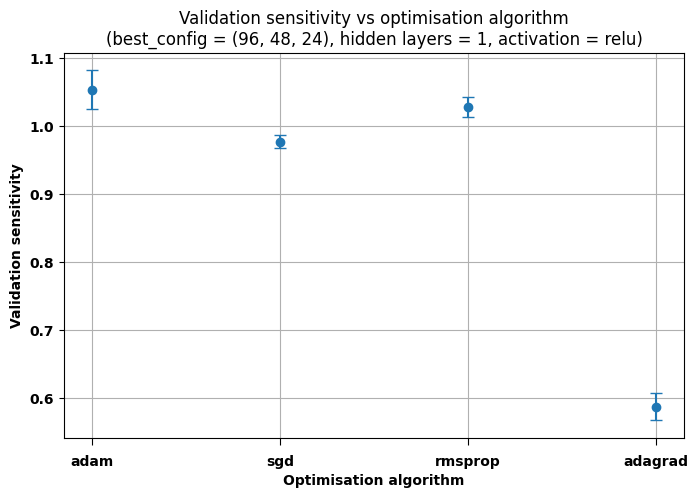

In [168]:
# plot validation sens vs optimation algorithm
plt.figure(figsize=(8,5))
plt.errorbar(
    results_optimizer_df["optimizer"],
    results_optimizer_df["val_sensitivity_mean"],
    yerr=results_optimizer_df["val_sensitivity_std"],
    fmt='o',
    capsize=4)
plt.xlabel("Optimisation algorithm")
plt.ylabel("Validation sensitivity")
plt.title(f"Validation sensitivity vs optimisation algorithm\n(best_config = {best_config}, hidden layers = {best_n_hidden_layers}, activation = {best_activation})")
plt.grid(True)
plt.show()

In [169]:
# extract info
print("Best node configuration used:", best_config)
print("Best number of hidden layers used:", best_n_hidden_layers)
print("Best activation function used:", best_activation)
print("Best validation sensitivity:", round(best_mean_sens_optimizer, 3))
print("Validation sensitivity spread:", round(best_std_sens_optimizer, 3))
print("Best optimisation algorithm:", best_optimizer)

Best node configuration used: (96, 48, 24)
Best number of hidden layers used: 1
Best activation function used: relu
Best validation sensitivity: 1.053
Validation sensitivity spread: 0.028
Best optimisation algorithm: adam


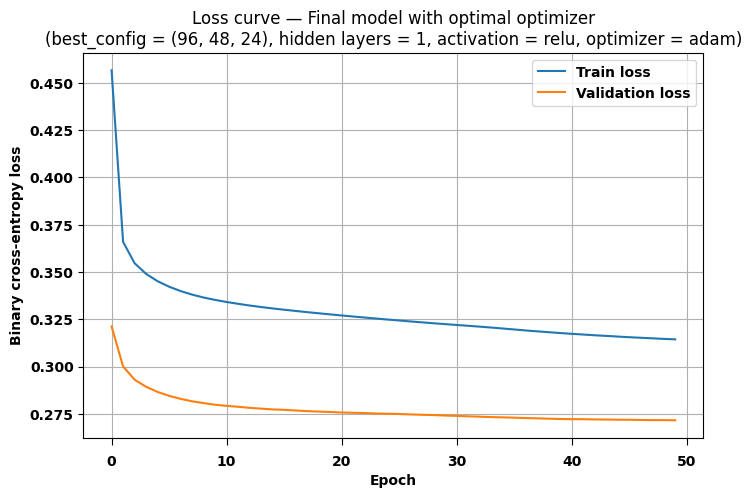

In [170]:
# build and train a final model 


final_model_optimizer = classifier_optimizer_scan(
    variables=variables,
    best_config=best_config,
    best_n_hidden_layers=best_n_hidden_layers,
    best_activation=best_activation,
    optimizer_obj=best_optimizer)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True)

history_optimizer = final_model_optimizer.fit(
    x_train,
    y_train,
    sample_weight=w_train,
    validation_data=(dset_val[0], dset_val[1]),
    epochs=50,
    batch_size=120,
    verbose=1,
    callbacks=[early_stop])

# plot loss 
plt.figure(figsize=(8,5))
plt.plot(history_optimizer.history['loss'], label='Train loss')
plt.plot(history_optimizer.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy loss')
plt.title(f'Loss curve — Final model with optimal optimizer\n(best_config = {best_config}, hidden layers = {best_n_hidden_layers}, activation = {best_activation}, optimizer = {best_optimizer})')
plt.legend()
plt.grid(True)
plt.show()

Final test sensitivity for optimal optimizer model: 2.405


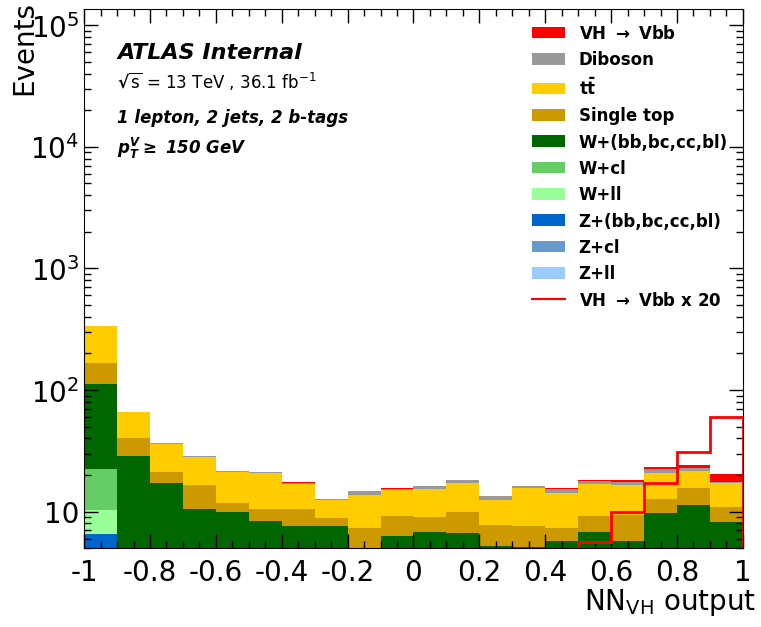

(<Figure size 850x700 with 1 Axes>,
 <Axes: xlabel='NN$_{VH}$ output', ylabel='Events'>)

In [171]:
# determine sens 
df_test_optimizer = df_test.copy()
df_test_optimizer["decision_value"] = final_model_optimizer.predict(dset_test[0], verbose=0).ravel()

test_sens_optimizer = sensitivity_NN(df_test_optimizer)[0]

print("Final test sensitivity for optimal optimizer model:", round(test_sens_optimizer, 3))
nn_output_plot(df_test_optimizer)

Final test sensitivity for optimal optimizer model is approximately 2.5, which is a reasonable result. 

## 8. Optimal loss function


In [174]:
# previous results 
print("Best node configuration:", best_config)
print("Best number of hidden layers:", best_n_hidden_layers)
print("Best activation function:", best_activation)
print("Best optimisation algorithm:", best_optimizer)

Best node configuration: (96, 48, 24)
Best number of hidden layers: 1
Best activation function: relu
Best optimisation algorithm: adam


In [175]:

def classifier_loss_scan(variables, best_config, best_n_hidden_layers, best_activation, optimizer_obj, loss_name):
    """
    classifier where loss function can be changed
    """
    num_variables = len(variables)
    n1, n2, n3 = best_config

    model = Sequential()
    model.add(Input(shape=(num_variables,)))

    if best_n_hidden_layers >= 1:
        model.add(Dense(n1, activation=best_activation))
    if best_n_hidden_layers >= 2:
        model.add(Dense(n2, activation=best_activation))
    if best_n_hidden_layers >= 3:
        model.add(Dense(n3, activation=best_activation))

    model.add(Dense(1, activation='sigmoid'))

    model.compile(
        loss=loss_name,
        optimizer=optimizer_obj,
        metrics=['accuracy'])

    return model

In [176]:
def get_val_sensitivity_loss(loss_name, epochs=30, batchSize=120, n_repeats=3):
    """
    evaluate the sensitivity obtained from the NN with different loss functions
    """

    
    sensitivities = []
   

    for i in range(n_repeats):
        K.clear_session()
        np.random.seed(42 + i)
        tf.random.set_seed(42 + i)

        # choose optimizer based on previous results
        if best_optimizer == "adam":
            optimizer_obj = Adam()

        elif best_optimizer == "sgd":
            optimizer_obj = SGD()

        elif best_optimizer == "rmsprop":
            optimizer_obj = RMSprop()

        elif best_optimizer == "adagrad":
            optimizer_obj = Adagrad()

        else:
            raise ValueError(f"Unknown optimizer: {best_optimizer}")
       
        model = classifier_loss_scan(
            variables=variables,
            best_config=best_config,
            best_n_hidden_layers=best_n_hidden_layers,
            best_activation=best_activation,
            optimizer_obj=best_optimizer,
            loss_name=loss_name)

        early_stop = EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True)

        model.fit(
            x_train,
            y_train,
            sample_weight=w_train,
            validation_data=(dset_val[0], dset_val[1]),
            epochs=epochs,
            batch_size=batchSize,
            verbose=0,
            callbacks=[early_stop])

        df_val_tmp = df_val.copy()
        df_val_tmp["decision_value"] = model.predict(dset_val[0], verbose=0).ravel()

        sens = sensitivity_NN(df_val_tmp)[0]
        sensitivities.append(sens)
       

    mean_sens = np.mean(sensitivities)
    std_sens = np.std(sensitivities)

   

    return mean_sens, std_sens

In [177]:
loss_options = ["binary_crossentropy", "mse", "mae"]

results_loss = []

best_mean_sens_loss = -999
best_std_sens_loss = None
best_loss = None


# loop
for loss_name in loss_options:
    mean_sens, std_sens = get_val_sensitivity_loss(
        loss_name=loss_name,
        epochs=30,
        batchSize=120,
        n_repeats=3)

    results_loss.append((loss_name, mean_sens, std_sens))

    print(f"Loss = {loss_name} -> validation sensitivity = {mean_sens:.3f} ± {std_sens:.3f}")

    if mean_sens > best_mean_sens_loss:
        best_mean_sens_loss = mean_sens
        best_std_sens_loss = std_sens
        best_loss = loss_name


Loss = binary_crossentropy -> validation sensitivity = 1.012 ± 0.015
Loss = mse -> validation sensitivity = 0.975 ± 0.004
Loss = mae -> validation sensitivity = 0.684 ± 0.022


In [178]:
# show in table
results_loss_df = pd.DataFrame(
    results_loss,
    columns=["loss_function", "val_sensitivity_mean", "val_sensitivity_std"])

display(results_loss_df)

,loss_function,val_sensitivity_mean,val_sensitivity_std
0,binary_crossentropy,1.011715,0.015113
1,mse,0.975400,0.003689
2,mae,0.684457,0.022214


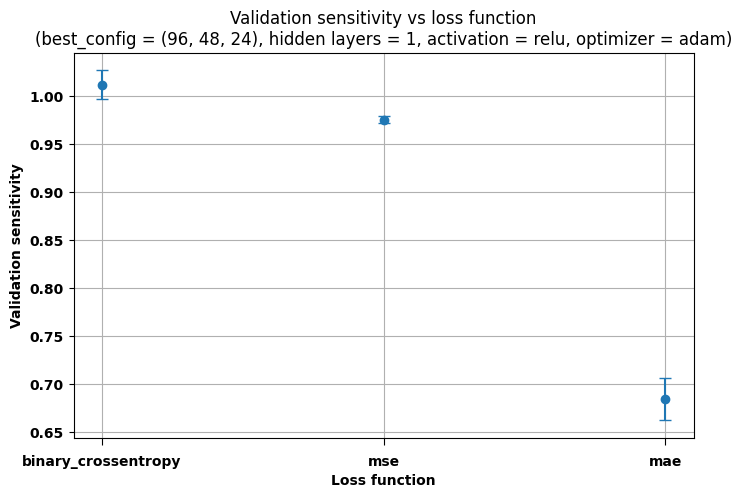

In [179]:
# plot val sens versus loss functions
plt.figure(figsize=(8,5))
plt.errorbar(
    results_loss_df["loss_function"],
    results_loss_df["val_sensitivity_mean"],
    yerr=results_loss_df["val_sensitivity_std"],
    fmt='o',
    capsize=4)
plt.xlabel("Loss function")
plt.ylabel("Validation sensitivity")
plt.title(f"Validation sensitivity vs loss function\n(best_config = {best_config}, hidden layers = {best_n_hidden_layers}, activation = {best_activation}, optimizer = {best_optimizer})")
plt.grid(True)
plt.show()

In [180]:
# extract results
print("Best node configuration used:", best_config)
print("Best number of hidden layers used:", best_n_hidden_layers)
print("Best activation function used:", best_activation)
print("Best optimisation algorithm used:", best_optimizer)
print("Best validation sensitivity:", round(best_mean_sens_loss, 3))
print("Validation sensitivity spread:", round(best_std_sens_loss, 3))
print("Best loss function:", best_loss)

Best node configuration used: (96, 48, 24)
Best number of hidden layers used: 1
Best activation function used: relu
Best optimisation algorithm used: adam
Best validation sensitivity: 1.012
Validation sensitivity spread: 0.015
Best loss function: binary_crossentropy


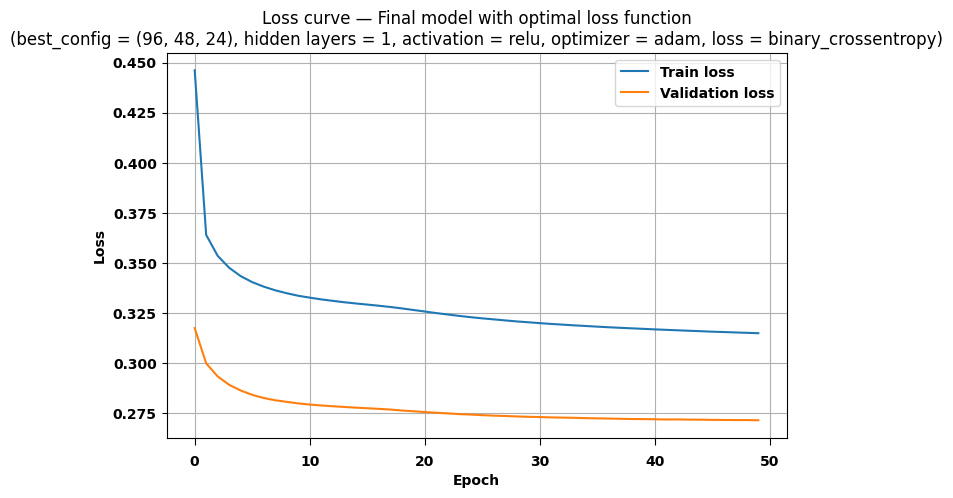

In [181]:

# build and train a final model

final_model_loss = classifier_loss_scan(
    variables=variables,
    best_config=best_config,
    best_n_hidden_layers=best_n_hidden_layers,
    best_activation=best_activation,
    optimizer_obj=best_optimizer,
    loss_name=best_loss)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True)

history_loss = final_model_loss.fit(
    x_train,
    y_train,
    sample_weight=w_train,
    validation_data=(dset_val[0], dset_val[1]),
    epochs=50,
    batch_size=120,
    verbose=1,
    callbacks=[early_stop])

# plot loss
plt.figure(figsize=(8,5))
plt.plot(history_loss.history['loss'], label='Train loss')
plt.plot(history_loss.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title(f'Loss curve — Final model with optimal loss function\n(best_config = {best_config}, hidden layers = {best_n_hidden_layers}, activation = {best_activation}, optimizer = {best_optimizer}, loss = {best_loss})')
plt.legend()
plt.grid(True)
plt.show()

Final test sensitivity for optimal loss-function model: 2.459


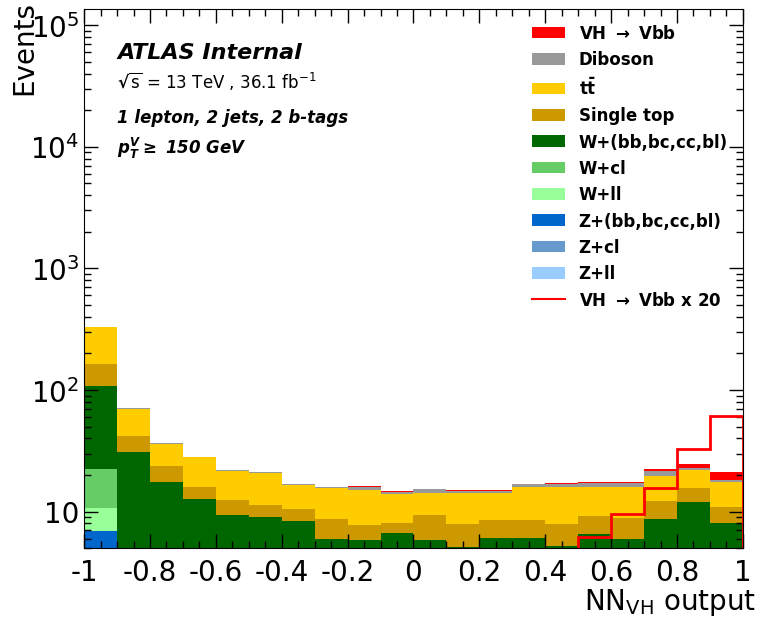

(<Figure size 850x700 with 1 Axes>,
 <Axes: xlabel='NN$_{VH}$ output', ylabel='Events'>)

In [182]:
# final sens
df_test_loss = df_test.copy()
df_test_loss["decision_value"] = final_model_loss.predict(dset_test[0], verbose=0).ravel()

test_sens_loss = sensitivity_NN(df_test_loss)[0]

print("Final test sensitivity for optimal loss-function model:", round(test_sens_loss, 3))
nn_output_plot(df_test_loss)

Final test sensitivity for optimal loss-function model is approximately 2.7, which is reasonable.

## 9. Training parameters
In this section, all previously optimised settings are used to evaluate different combinations of learning rate and batch size for model training. This allows the effect of the main training parameters to be studied while keeping the optimised network architecture fixed.

In [185]:

# Training-parameter optimisation
# Uses:
# all variables, all events
# best_n_hidden_layers, best n of nodes
# best_activation
# best_optimizer
# best_loss


# check previously optimised settings
print("Best node configuration:", best_config)
print("Best number of hidden layers:", best_n_hidden_layers)
print("Best activation function:", best_activation)
print("Best optimisation algorithm:", best_optimizer)
print("Best loss function:", best_loss)



def classifier_training_params_scan(
    variables,
    best_config,
    best_n_hidden_layers,
    best_activation,
    optimizer_obj,
    best_loss,
    learning_rate):
    
    """
    Model with all previously optimised settings, but training parameters will vary: learning_rate
    """
    num_variables = len(variables)
    n1, n2, n3 = best_config

    model = Sequential()
    model.add(Input(shape=(num_variables,)))

    if best_n_hidden_layers >= 1:
        model.add(Dense(n1, activation=best_activation))
    if best_n_hidden_layers >= 2:
        model.add(Dense(n2, activation=best_activation))
    if best_n_hidden_layers >= 3:
        model.add(Dense(n3, activation=best_activation))

    model.add(Dense(1, activation='sigmoid'))

    model.compile(
        loss=best_loss,
        optimizer=optimizer_obj,
        metrics=['accuracy'])

    return model




Best node configuration: (96, 48, 24)
Best number of hidden layers: 1
Best activation function: relu
Best optimisation algorithm: adam
Best loss function: binary_crossentropy


In [186]:
def get_val_sensitivity_training_params(
    learning_rate,
    batch_size,
    epochs=30,
    n_repeats=3):
    """
    evaluate sensitivity for different learning rates and batch size
    """
    sensitivities = []


    for i in range(n_repeats):
        K.clear_session()
        np.random.seed(42 + i)
        tf.random.set_seed(42 + i)
        # choose optimizer based on previous results
        if best_optimizer == "adam":
            optimizer_obj = Adam()

        elif best_optimizer == "sgd":
            optimizer_obj = SGD()

        elif best_optimizer == "rmsprop":
            optimizer_obj = RMSprop()

        elif best_optimizer == "adagrad":
            optimizer_obj = Adagrad()

        else:
            raise ValueError(f"Unknown optimizer: {best_optimizer}")

        
        model = classifier_training_params_scan(
            variables=variables,
            best_config=best_config,
            best_n_hidden_layers=best_n_hidden_layers,
            best_activation=best_activation,
            optimizer_obj=best_optimizer,
            best_loss=best_loss,
            learning_rate=learning_rate)

        early_stop = EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True)

        model.fit(
            x_train,
            y_train,
            sample_weight=w_train,
            validation_data=(dset_val[0], dset_val[1]),
            epochs=epochs,
            batch_size=batch_size,
            verbose=0,
            callbacks=[early_stop])

        df_val_tmp = df_val.copy()
        df_val_tmp["decision_value"] = model.predict(dset_val[0], verbose=0).ravel()

        sens = sensitivity_NN(df_val_tmp)[0]
        sensitivities.append(sens)


    mean_sens = np.mean(sensitivities)
    std_sens = np.std(sensitivities)



    return mean_sens, std_sens




In [187]:
#Grid of training parameters

learning_rates = [0.0001, 0.0005, 0.001, 0.005]
batch_sizes = [32, 64, 120, 256]

results_train_params = []

best_mean_sens_train = -999
best_std_sens_train = None
best_train_params = None


# loop over
for lr in learning_rates:
    for bs in batch_sizes:
        mean_sens, std_sens = get_val_sensitivity_training_params(
            learning_rate=lr,
            batch_size=bs,
            epochs=30,
            n_repeats=3)

        results_train_params.append((lr, bs, mean_sens, std_sens))

        print(f"learning rate = {lr}, batch size = {bs} -> validation sensitivity = {mean_sens:.3f} ± {std_sens:.3f}")

        if mean_sens > best_mean_sens_train:
            best_mean_sens_train = mean_sens
            best_std_sens_train = std_sens
            best_train_params = (lr, bs)





learning rate = 0.0001, batch size = 32 -> validation sensitivity = 1.069 ± 0.038
learning rate = 0.0001, batch size = 64 -> validation sensitivity = 1.020 ± 0.020
learning rate = 0.0001, batch size = 120 -> validation sensitivity = 1.032 ± 0.007
learning rate = 0.0001, batch size = 256 -> validation sensitivity = 1.030 ± 0.014
learning rate = 0.0005, batch size = 32 -> validation sensitivity = 1.045 ± 0.030
learning rate = 0.0005, batch size = 64 -> validation sensitivity = 1.033 ± 0.015
learning rate = 0.0005, batch size = 120 -> validation sensitivity = 1.011 ± 0.009
learning rate = 0.0005, batch size = 256 -> validation sensitivity = 1.023 ± 0.024
learning rate = 0.001, batch size = 32 -> validation sensitivity = 1.040 ± 0.018
learning rate = 0.001, batch size = 64 -> validation sensitivity = 1.044 ± 0.019
learning rate = 0.001, batch size = 120 -> validation sensitivity = 1.008 ± 0.014
learning rate = 0.001, batch size = 256 -> validation sensitivity = 1.016 ± 0.013
learning rate 

,learning_rate,batch_size,val_sensitivity_mean,val_sensitivity_std
0,0.0001,32,1.068568,0.037994
1,0.0001,64,1.019734,0.020479
2,0.0001,120,1.031734,0.006850
3,0.0001,256,1.029745,0.014049
4,0.0005,32,1.045444,0.029676
5,0.0005,64,1.033348,0.014808
6,0.0005,120,1.011312,0.008951
7,0.0005,256,1.022976,0.023873
8,0.0010,32,1.039696,0.018301
9,0.0010,64,1.044175,0.019494


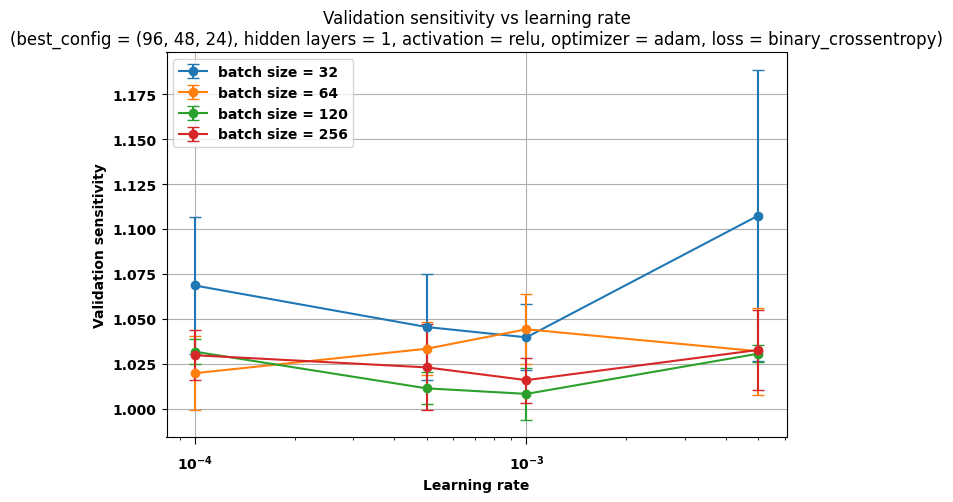

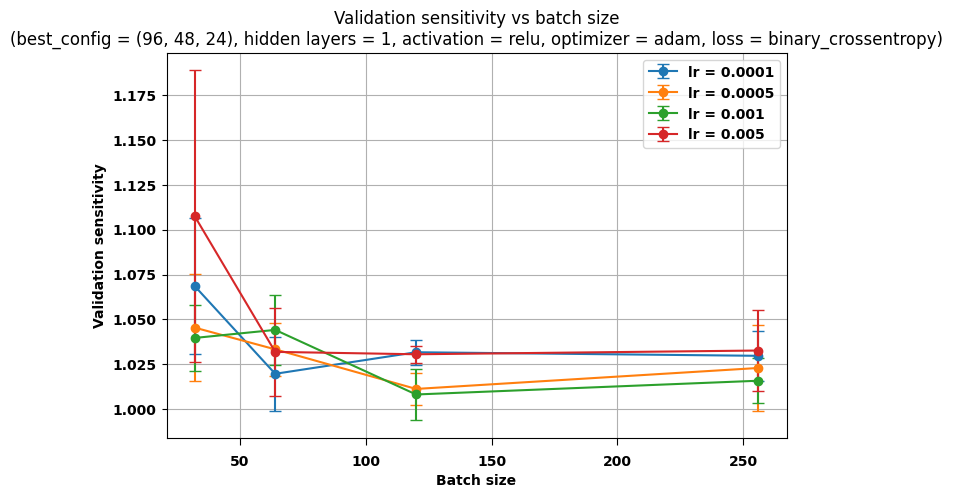

In [188]:
# Results table
results_train_params_df = pd.DataFrame(
    results_train_params,
    columns=["learning_rate", "batch_size", "val_sensitivity_mean", "val_sensitivity_std"])

display(results_train_params_df)


# Plot sensitivity vs learning rate for each batch size

plt.figure(figsize=(8,5))

for bs in batch_sizes:
    subset = results_train_params_df[results_train_params_df["batch_size"] == bs]
    plt.errorbar(
        subset["learning_rate"],
        subset["val_sensitivity_mean"],
        yerr=subset["val_sensitivity_std"],
        marker='o',
        capsize=4,
        label=f"batch size = {bs}")

plt.xscale('log')
plt.xlabel("Learning rate")
plt.ylabel("Validation sensitivity")
plt.title(
    f"Validation sensitivity vs learning rate\n"
    f"(best_config = {best_config}, hidden layers = {best_n_hidden_layers}, "
    f"activation = {best_activation}, optimizer = {best_optimizer}, loss = {best_loss})")
plt.legend()
plt.grid(True)
plt.show()


#  Plot sensitivity vs batch size for each learning rate

plt.figure(figsize=(8,5))

for lr in learning_rates:
    subset = results_train_params_df[results_train_params_df["learning_rate"] == lr]
    plt.errorbar(
        subset["batch_size"],
        subset["val_sensitivity_mean"],
        yerr=subset["val_sensitivity_std"],
        marker='o',
        capsize=4,
        label=f"lr = {lr}")

plt.xlabel("Batch size")
plt.ylabel("Validation sensitivity")
plt.title(
    f"Validation sensitivity vs batch size\n"
    f"(best_config = {best_config}, hidden layers = {best_n_hidden_layers}, "
    f"activation = {best_activation}, optimizer = {best_optimizer}, loss = {best_loss})")
plt.legend()
plt.grid(True)
plt.show()




In [189]:
# extract info

print("Best validation sensitivity:", round(best_mean_sens_train, 3))
print("Validation sensitivity spread:", round(best_std_sens_train, 3))
print("Best training parameters (learning rate, batch size):", best_train_params)



Best validation sensitivity: 1.107
Validation sensitivity spread: 0.081
Best training parameters (learning rate, batch size): (0.005, 32)


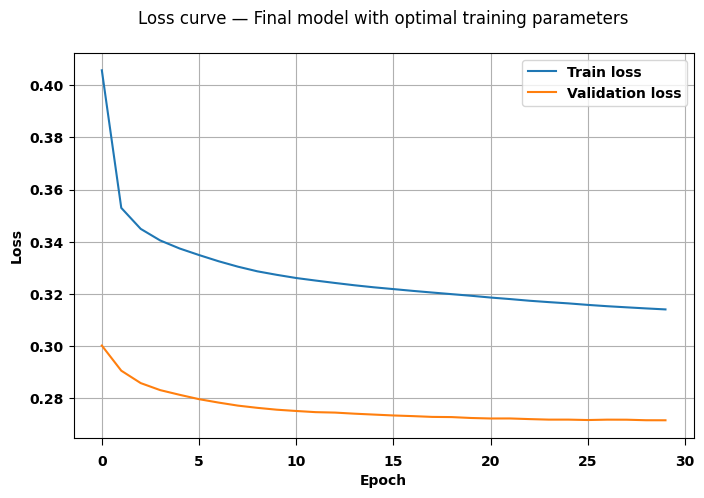

In [190]:

# build and train final model

best_lr, best_bs = best_train_params

final_model_train = classifier_training_params_scan(
    variables=variables,
    best_config=best_config,
    best_n_hidden_layers=best_n_hidden_layers,
    best_activation=best_activation,
    optimizer_obj=best_optimizer,
    best_loss=best_loss,
    learning_rate=best_lr)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True)

history_train = final_model_train.fit(
    x_train,
    y_train,
    sample_weight=w_train,
    validation_data=(dset_val[0], dset_val[1]),
    epochs=30,
    batch_size=best_bs,
    verbose=1,
    callbacks=[early_stop])


# Plot loss curve 

plt.figure(figsize=(8,5))
plt.plot(history_train.history['loss'], label='Train loss')
plt.plot(history_train.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title(f"Loss curve — Final model with optimal training parameters\n")
plt.legend()
plt.grid(True)
plt.show()



Final test sensitivity for optimal training-parameter model: 2.436


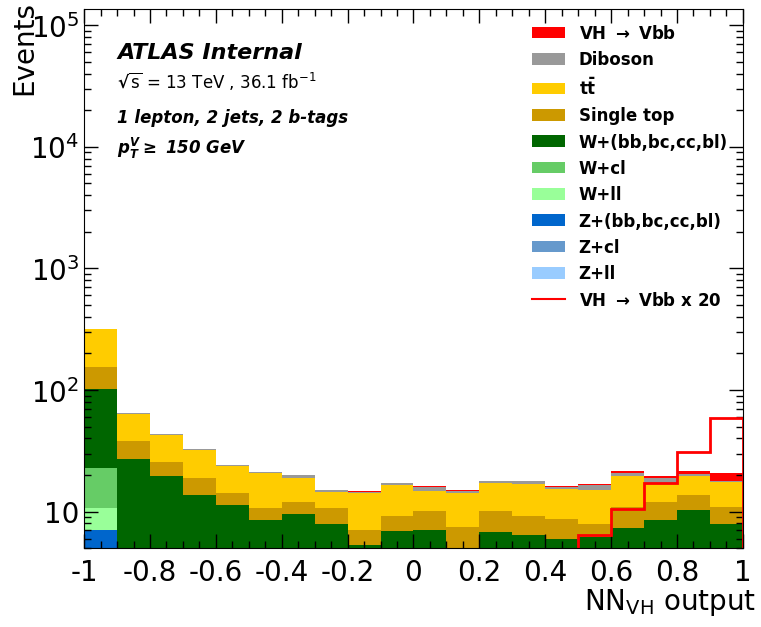

(<Figure size 850x700 with 1 Axes>,
 <Axes: xlabel='NN$_{VH}$ output', ylabel='Events'>)

In [191]:
# final sens 

df_test_train = df_test.copy()
df_test_train["decision_value"] = final_model_train.predict(dset_test[0], verbose=0).ravel()

test_sens_train = sensitivity_NN(df_test_train)[0]

print("Final test sensitivity for optimal training-parameter model:", round(test_sens_train, 3))
nn_output_plot(df_test_train)

After optimising the training parameters together with all previously determined optimal settings, the model achieves a sensitivity of approximately 2.7, which is a reasonable result. All optimised hyperparameters can now be combined to train the final model. The final model is going to be trained using multiple random seeds in order to assess the stability and robustness of the neural network performance.

## 10. Summary of the optimisation studies
The results of the optimisation studies above are summarised below and are used to select the optimal neural network architecture for the final model in the next section.


In [194]:
# input variables
display(history_df[["step", "n_variables", "removed_variable", "val_sensitivity_mean", "val_sensitivity_std"]])

#nodes at each layer
results_df = pd.DataFrame(
    results,
    columns=["nodes_layer1", "nodes_layer2", "nodes_layer3", "val_sensitivity_mean", "val_sensitivity_std"])

display(results_df)

#number of layers
results_layers_df = pd.DataFrame(
    results_layers,
    columns=["n_hidden_layers", "val_sensitivity_mean", "val_sensitivity_std"])

display(results_layers_df)

# activation function
results_activation_df = pd.DataFrame(
    results_activation,
    columns=["activation_function", "val_sensitivity_mean", "val_sensitivity_std"])

display(results_activation_df)


#optimizer
results_optimizer_df = pd.DataFrame(
    results_optimizer,
    columns=["optimizer", "val_sensitivity_mean", "val_sensitivity_std"])

display(results_optimizer_df)


#loss function
results_loss_df = pd.DataFrame(
    results_loss,
    columns=["loss_function", "val_sensitivity_mean", "val_sensitivity_std"])

display(results_loss_df)

#training parameters
results_train_params_df = pd.DataFrame(
    results_train_params,
    columns=["learning_rate", "batch_size", "val_sensitivity_mean", "val_sensitivity_std"])

display(results_train_params_df)

,step,n_variables,removed_variable,val_sensitivity_mean,val_sensitivity_std
0,0,14,NONE,1.058125,0.014673
1,1,13,nTrackJetsOR,1.053387,0.032921
2,2,12,mTW,1.071460,0.014471
3,3,11,dYWH,1.079270,0.018377
4,4,10,dPhiVBB,1.064055,0.034001
5,5,9,MV1cB2_cont,1.058073,0.043287
6,6,8,pTB2,1.027936,0.027185
7,7,7,nTags,1.012241,0.024513
8,8,6,nJ,1.029397,0.007526
9,9,5,MET,0.976298,0.008602


,nodes_layer1,nodes_layer2,nodes_layer3,val_sensitivity_mean,val_sensitivity_std
0,8,4,2,0.993684,0.062718
1,16,8,4,1.015592,0.012240
2,24,12,6,1.041452,0.023490
3,32,16,8,1.047074,0.017442
4,48,24,12,1.055696,0.008664
5,64,32,16,1.035417,0.020585
6,96,48,24,1.056250,0.020719
7,128,64,32,1.044243,0.023988


,n_hidden_layers,val_sensitivity_mean,val_sensitivity_std
0,1,1.052753,0.041141
1,2,1.050655,0.005312
2,3,1.038178,0.017655


,activation_function,val_sensitivity_mean,val_sensitivity_std
0,relu,1.031273,0.017546
1,tanh,1.005036,0.010466
2,elu,0.985511,0.015268
3,selu,1.010830,0.005031


,optimizer,val_sensitivity_mean,val_sensitivity_std
0,adam,1.053355,0.028402
1,sgd,0.976599,0.009625
2,rmsprop,1.027900,0.015142
3,adagrad,0.587773,0.019927


,loss_function,val_sensitivity_mean,val_sensitivity_std
0,binary_crossentropy,1.011715,0.015113
1,mse,0.975400,0.003689
2,mae,0.684457,0.022214


,learning_rate,batch_size,val_sensitivity_mean,val_sensitivity_std
0,0.0001,32,1.068568,0.037994
1,0.0001,64,1.019734,0.020479
2,0.0001,120,1.031734,0.006850
3,0.0001,256,1.029745,0.014049
4,0.0005,32,1.045444,0.029676
5,0.0005,64,1.033348,0.014808
6,0.0005,120,1.011312,0.008951
7,0.0005,256,1.022976,0.023873
8,0.0010,32,1.039696,0.018301
9,0.0010,64,1.044175,0.019494


## 11. FINAL OPTIMISED MODEL
Multi-seed evaluation is used: the NN model is stochastic so reporting mean ± std sensitivity over a few seeds is more robust than quoting one run. Multi-seed method evaluates the stability of the neural network trained. 
First, the results of the optimisation studies are analysed to determine an appropriate neural network architecture. Using this architecture, the final optimised model is constructed and evaluated across eight random seeds to assess its stability and obtain the final sensitivity.



In [196]:
best_optimizer = 'adam'
best_loss = 'binary_crossentropy'
best_lr = 0.0005
best_bs = 64
best_n_hidden_layers = 3
best_activation = 'elu'
best_config = (48, 24, 12)

# using this set of 12 input variables gives the best result
best_variables = ["nJ",
    "nTags",
    "dRBB",
    "pTB1",
    "pTB2",
    "pTV",
    "Mtop",
    "MET",
    "dYWH",
    "MV1cB1_cont",
    "MV1cB2_cont",
    "nTrackJetsOR"]



print("Best variables:", best_variables)
print("Best node configuration:", best_config)
print("Best number of hidden layers:", best_n_hidden_layers)
print("Best activation function:", best_activation)
print("Best optimisation algorithm: adam")
print("Best loss function:", best_loss)
print("Best learning rate:", best_lr)
print("Best batch size:", best_bs)

Best variables: ['nJ', 'nTags', 'dRBB', 'pTB1', 'pTB2', 'pTV', 'Mtop', 'MET', 'dYWH', 'MV1cB1_cont', 'MV1cB2_cont', 'nTrackJetsOR']
Best node configuration: (48, 24, 12)
Best number of hidden layers: 3
Best activation function: elu
Best optimisation algorithm: adam
Best loss function: binary_crossentropy
Best learning rate: 0.0005
Best batch size: 64


The following cell allows the fraction of background training data to be varied as required. Since we have already chosen to use all available signal training events, the number of signal events remains fixed.

In [198]:

# reduce background stats

frac_bkg = 1

df_train_sig = df_train[df_train["Class"] == 1].copy()
df_train_bkg = df_train[df_train["Class"] == 0].copy()

df_train_bkg_reduced = df_train_bkg.sample(
    frac=frac_bkg,
    random_state=42)

#combine and shuffle
df_train_final = pd.concat(
    [df_train_sig, df_train_bkg_reduced],
    axis=0)

df_train_final = df_train_final.sample(
    frac=1,
    random_state=42).reset_index(drop=True)

print("Signal used:", len(df_train_sig))
print("Background used:", len(df_train_bkg_reduced))
print("Total training events:", len(df_train_final))



# scale data

x_train_final, y_train_final, w_train_final, dset_val_final, dset_test_final = scale_prepare_data(
    df_train_final,
    df_val,
    df_test,
    best_variables,
    scaler='standard')

Signal used: 50449
Background used: 26727
Total training events: 77176


In [199]:
def final_optimised_model(best_variables, best_config, best_n_hidden_layers,
                          best_activation, optimizer_obj, best_loss,
                          learning_rate=best_lr):
    num_variables = len(best_variables)
    n1, n2, n3 = best_config


    model = Sequential()
    model.add(Input(shape=(num_variables,)))

    if best_n_hidden_layers >= 1:
        model.add(Dense(n1, activation=best_activation))
    if best_n_hidden_layers >= 2:
        model.add(Dense(n2, activation=best_activation))
    if best_n_hidden_layers >= 3:
        model.add(Dense(n3, activation=best_activation))

    model.add(Dense(1, activation='sigmoid'))

    model.compile(
        loss=best_loss,
        optimizer=optimizer_obj,
        metrics=['accuracy'])

    return model

In [200]:
import random

seeds = [1, 2, 3, 4, 5,6,7,8]

test_sensitivities = []
histories = []
models = []
test_dfs = []

for seed in seeds:
    print(f"\nRunning final model with seed = {seed}")

    # fix randomness
    K.clear_session()
    np.random.seed(seed)
    tf.random.set_seed(seed)
    random.seed(seed)

    # build model
    final_model = final_optimised_model(
        best_variables=best_variables,
        best_config=best_config,
        best_n_hidden_layers=best_n_hidden_layers,
        best_activation=best_activation,
        optimizer_obj=best_optimizer,
        best_loss=best_loss,
        learning_rate=best_lr)

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True)

    # train
    history_final_model = final_model.fit(
        x_train_final,
        y_train_final,
        sample_weight=w_train_final,
        validation_data=(dset_val_final[0], dset_val_final[1]),
        epochs=30,
        batch_size=best_bs,
        verbose=1,
        callbacks=[early_stop])

    # test evaluation
    df_test_final_model = df_test.copy()
    df_test_final_model["decision_value"] = final_model.predict(
        dset_test_final[0], verbose=0).ravel()

    final_test_sensitivity = sensitivity_NN(df_test_final_model)[0]

    print(f"Test sensitivity for seed {seed}: {final_test_sensitivity:.3f}")

    test_sensitivities.append(final_test_sensitivity)
    histories.append(history_final_model)
    models.append(final_model)
    test_dfs.append(df_test_final_model)


Running final model with seed = 1
Test sensitivity for seed 1: 2.502

Running final model with seed = 2
Test sensitivity for seed 2: 2.329

Running final model with seed = 3
Test sensitivity for seed 3: 2.420

Running final model with seed = 4
Test sensitivity for seed 4: 2.611

Running final model with seed = 5
Test sensitivity for seed 5: 2.518

Running final model with seed = 6
Test sensitivity for seed 6: 2.298

Running final model with seed = 7
Test sensitivity for seed 7: 2.513

Running final model with seed = 8
Test sensitivity for seed 8: 2.393


In [201]:
# summary: mean and std sensitivity of final model
mean_test_sens = np.mean(test_sensitivities)
std_test_sens = np.std(test_sensitivities)

print("\nFinal fully optimised model over 8 seeds")
print("Seeds used:", seeds)
print("Test sensitivities:", [round(x, 3) for x in test_sensitivities])
print("Mean test sensitivity:", round(mean_test_sens, 3))
print("Std test sensitivity:", round(std_test_sens, 3))


Final fully optimised model over 8 seeds
Seeds used: [1, 2, 3, 4, 5, 6, 7, 8]
Test sensitivities: [2.502, 2.329, 2.42, 2.611, 2.518, 2.298, 2.513, 2.393]
Mean test sensitivity: 2.448
Std test sensitivity: 0.099


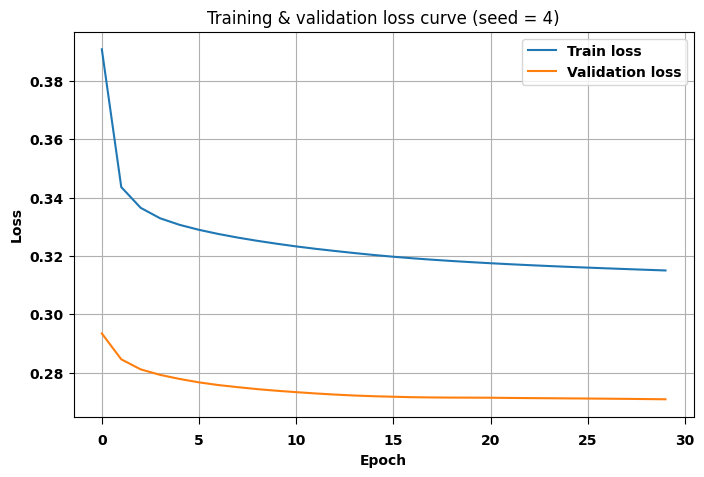

In [202]:
# plot loss curve for only one seed (best seed)
plt.figure(figsize=(8, 5))
plt.plot(histories[3].history['loss'], label='Train loss')
plt.plot(histories[3].history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title(f'Training & validation loss curve (seed = {seeds[3]})')
plt.legend()
plt.grid(True)
plt.show()


Best seed: 4
Best sensitivity: 2.611


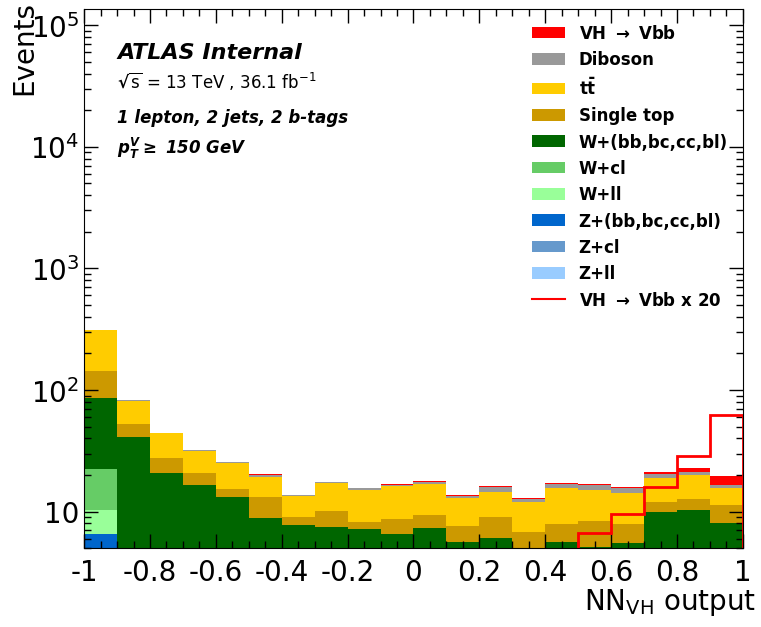

(<Figure size 850x700 with 1 Axes>,
 <Axes: xlabel='NN$_{VH}$ output', ylabel='Events'>)

In [203]:
# extract info from the best seed and compute the nn output plot
best_idx = np.argmax(test_sensitivities)

print("\nBest seed:", seeds[best_idx])
print("Best sensitivity:", round(test_sensitivities[best_idx], 3))

nn_output_plot(test_dfs[best_idx])

In [204]:
print("FINAL OPTIMISED MODEL SETTINGS")
print("Variables:", best_variables)
print("Node configuration:", best_config)
print("Number of hidden layers:", best_n_hidden_layers)
print("Activation function:", best_activation)
print("Optimisation algorithm:", best_optimizer)
print("Loss function:", best_loss)
print("Learning rate:", best_lr)
print("Batch size:", best_bs)
print("Final test sensitivity:", round(mean_test_sens, 3), "+-", round(std_test_sens, 3))

FINAL OPTIMISED MODEL SETTINGS
Variables: ['nJ', 'nTags', 'dRBB', 'pTB1', 'pTB2', 'pTV', 'Mtop', 'MET', 'dYWH', 'MV1cB1_cont', 'MV1cB2_cont', 'nTrackJetsOR']
Node configuration: (48, 24, 12)
Number of hidden layers: 3
Activation function: elu
Optimisation algorithm: adam
Loss function: binary_crossentropy
Learning rate: 0.0005
Batch size: 64
Final test sensitivity: 2.448 +- 0.099


## Observations
Fully optimised model might give a lower sensitivity than partially optimised model: The final optimised model does not necessarily achieve the highest sensitivity observed during intermediate optimisation steps. This is because individual training runs are subject to statistical fluctuations and random initialisation, and the optimisation procedure is based on validation performance rather than test performance. The final model represents a more robust and consistent configuration rather than the most favourable fluctuation.


Best seed: 4
Best test sensitivity: 2.611382501020485


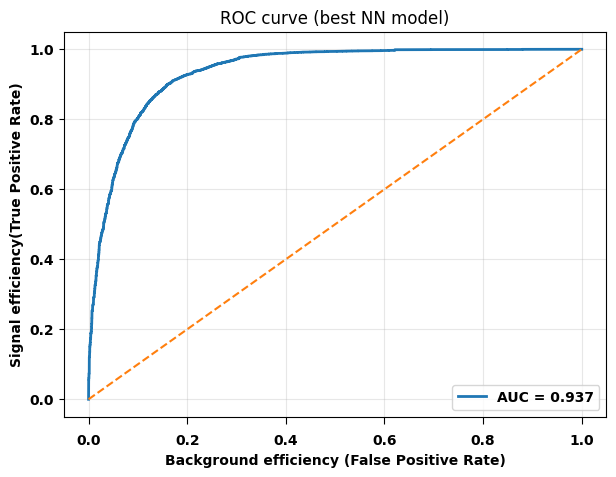

In [206]:
from sklearn.metrics import roc_curve, auc
# plot the roc curve for the best seed

#  best seed 
best_idx = np.argmax(test_sensitivities)

print("Best seed:", seeds[best_idx])
print("Best test sensitivity:", test_sensitivities[best_idx])

# dataframe corresponding to best model
df_best = test_dfs[best_idx]

# true labels and NN scores
y_true = df_best["Class"].values
y_score = df_best["decision_value"].values
y_weight = df_best["EventWeight"].values

# compute ROC
fpr, tpr, thresholds = roc_curve(
    y_true,
    y_score,
    sample_weight=y_weight)

roc_auc = auc(fpr, tpr)

# plot
plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {roc_auc:.3f}")

plt.plot([0,1], [0,1], linestyle="--")

plt.xlabel("Background efficiency (False Positive Rate)")
plt.ylabel("Signal efficiency(True Positive Rate)")
plt.title("ROC curve (best NN model)")
plt.legend(loc="lower right")

plt.grid(alpha=0.3)
plt.show()

The ROC curve of the best-seed final model gives an AUC of 0.934, indicating very strong discrimination between signal and background events using this classifier model. The best-performing seed achieves a test sensitivity of approximately 2.5, while the mean sensitivity across eight seeds is about 2.4. This represents a clear improvement compared to both the simplest neural network configuration and the cut-based analysis, demonstrating the benefit of the application of an optimisation procedure to the machine learning method. 